# MLP — Perceptron Multi-Couches : cas de tests

Cette section valide notre implémentation du **Perceptron Multi-Couches (PMC / MLP)**, écrite en **C++** (`src/MLP.cpp`)
et appelée depuis Python via `ctypes` (`python/mlp_wrapper.py`), sur les 11 cas de tests du cours
(6 en classification, 5 en régression), avec les deux fonctions d'activation demandées : **Tanh** et **Sigmoïde**.

**Rappel du cours (slides 86 à 95).** Chaque neurone calcule `x_j^l = θ(Σ_i w_ij^l · x_i^(l-1))` avec `x_0 = 1` (biais).
La rétropropagation du gradient stochastique répète : tirer **un exemple au hasard**, puis

| | Classification | Régression |
|---|---|---|
| Sortie (couche L) | `δ_j^L = θ'(x_j^L) · (x_j^L − y_j)` | `δ_j^L = x_j^L − y_j` (sortie **linéaire**) |
| Couches cachées | `δ_i^(l-1) = θ'(x_i^(l-1)) · Σ_j w_ij^l · δ_j^l` | idem |
| Mise à jour | `w_ij^l ← w_ij^l − α · x_i^(l-1) · δ_j^l` | idem |

avec `θ'(x) = 1 − x²` pour **Tanh** (cours) et `θ'(x) = x(1 − x)` pour la **Sigmoïde** (dérivée de σ(s) = 1/(1+e^-s), exprimée avec la sortie x).

**Conventions.** Les étiquettes de classification sont fournies en {-1, 1} (comme dans le notebook « Cas de Tests »).
Avec la Sigmoïde (sortie dans ]0, 1[), la bibliothèque les convertit en {0, 1}. Une *époque* = autant d'itérations que d'exemples.

**Plan** : 1. Mise en place · 2. Classification (6 cas) · 3. Régression (5 cas) · 4. Impact des paramètres sur la convergence · 5. Synthèse.

## 1. Mise en place

In [1]:
import os, sys, subprocess
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100

# ----------------------------------------------------------------------------- chemins (à adapter si besoin)
def premier_existant(candidats, fichier):
    for d in candidats:
        if os.path.exists(os.path.join(d, fichier)):
            return d
    raise FileNotFoundError(f"{fichier} introuvable dans {candidats}")

WRAPPER_DIR = premier_existant(["../python", "python", "."], "mlp_wrapper.py")
sys.path.insert(0, os.path.abspath(WRAPPER_DIR))
import mlp_wrapper as mw
from mlp_wrapper import MLP

SRC_CPP = "../src/MLP.cpp"
LIB_PATH = None   # <- si la bibliothèque (.dll / .so) n'est pas trouvée automatiquement, mets son chemin ici
RESULTS = "../results/MLP"
CROSS_DOSSIER = "Coss"   # nom du dossier du cas « Cross » dans results/ (écrit « Coss » dans l'arborescence actuelle)


def trouver_ou_compiler_lib():
    """Cherche la bibliothèque compilée ; sinon la compile avec g++ (Linux / macOS)."""
    if LIB_PATH:
        return LIB_PATH
    noms = ["libmlp.so", "libmlp.dylib", "mlp.dll", "libmlp.dll"]
    for d in [WRAPPER_DIR, "../build", "../cmake-build-debug", ".."]:
        for n in noms:
            if os.path.exists(os.path.join(d, n)):
                return os.path.join(d, n)
    sortie = os.path.join(WRAPPER_DIR, "libmlp.so")
    cmd = ["g++", "-std=c++20", "-shared", "-fPIC", "-O2", "-o", sortie, SRC_CPP]
    print("Compilation :", " ".join(cmd))
    try:
        subprocess.run(cmd, check=True)
    except Exception as e:
        raise RuntimeError("Compilation impossible. Compile src/MLP.cpp en bibliothèque dynamique "
                           "puis renseigne LIB_PATH.") from e
    return sortie

LIB_FILE = trouver_ou_compiler_lib()
mw.load_library(LIB_FILE)
print("Bibliothèque C++ chargée :", os.path.abspath(LIB_FILE))

Bibliothèque C++ chargée : /Users/nadinezrg/Desktop/PA/python/libmlp.so


In [2]:
# ----------------------------------------------------------------------------- outils communs
COULEUR = {"tanh": "tab:orange", "sigmoid": "tab:green"}
NOM = {"tanh": "Tanh", "sigmoid": "Sigmoïde"}
RESUME = []   # une ligne par (cas, activation), affichée dans la synthèse finale


def sauver(fig, categorie, cas, nom):
    """Enregistre la figure dans results/MLP/<categorie>/<cas>/<nom>."""
    dossier = os.path.join(RESULTS, categorie, cas)
    os.makedirs(dossier, exist_ok=True)
    fig.savefig(os.path.join(dossier, nom), dpi=120, bbox_inches="tight")


def entrainer(layers, activation, task, X, Y, alpha, epochs, seed, critere=None, essais=1,
              X_val=None, Y_val=None, log_every=None):
    """
    Entraîne un MLP. Si 'critere' est donné, on relance avec une autre graine d'initialisation des poids
    (jusqu'à 'essais' fois) tant que le critère n'est pas satisfait. On garde le meilleur modèle (loss minimale).
    """
    meilleur = None
    for k in range(essais):
        m = MLP(layers, activation=activation, task=task, seed=seed + k)
        h = m.fit(X, Y, alpha=alpha, epochs=epochs, X_val=X_val, Y_val=Y_val, log_every=log_every)
        if meilleur is None or h["train_loss"][-1] < meilleur[1]["train_loss"][-1]:
            meilleur = (m, h, seed + k, k + 1)
        if critere is None or critere(m):
            meilleur = (m, h, seed + k, k + 1)
            break
    return meilleur   # (modèle, historique, graine utilisée, nombre d'essais)


def grille_2D(X, marge=0.3, n=120):
    x0, x1 = X[:, 0].min() - marge, X[:, 0].max() + marge
    y0, y1 = X[:, 1].min() - marge, X[:, 1].max() + marge
    xx, yy = np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))
    return xx, yy, np.c_[xx.ravel(), yy.ravel()]


def tracer_regions(ax, model, X, Y, titre):
    """Régions de décision du MLP (classification, entrées en 2D) + exemples."""
    xx, yy, G = grille_2D(X)
    Y = np.asarray(Y).reshape(len(X), -1)
    if model.n_outputs == 1:
        zone = model.predict_class(G).reshape(xx.shape)           # -1 ou +1
        ax.contourf(xx, yy, zone, levels=[-2, 0, 2], colors=["#f4a6a6", "#a6c8f4"], alpha=0.8)
        ax.scatter(X[Y[:, 0] == 1, 0], X[Y[:, 0] == 1, 1], color="blue", edgecolor="k", s=25)
        ax.scatter(X[Y[:, 0] == -1, 0], X[Y[:, 0] == -1, 1], color="red", edgecolor="k", s=25)
    else:
        zone = np.argmax(model.predict(G), axis=1).reshape(xx.shape)
        ax.contourf(xx, yy, zone, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#a6c8f4", "#f4a6a6", "#a6e0a6"], alpha=0.8)
        for c, col in enumerate(["blue", "red", "green"]):
            sel = Y[:, c] == 1
            ax.scatter(X[sel, 0], X[sel, 1], color=col, edgecolor="k", s=18)
    ax.set_title(titre)
    ax.set_xlabel("x1"); ax.set_ylabel("x2")


def tracer_courbe(ax, hists, cle, titre, ylabel, log=False, noms=None):
    """Courbes d'apprentissage (une par activation). Si 'val_...' existe, il est tracé en pointillés."""
    noms = noms or NOM
    for act, h in hists.items():
        ax.plot(h["epoch"], h[cle], color=COULEUR[act], label=f"{noms[act]} (train)")
        if "val_" + cle.split("_", 1)[1] in h:
            ax.plot(h["epoch"], h["val_" + cle.split("_", 1)[1]], "--", color=COULEUR[act], label=f"{noms[act]} (test)")
    if log:
        ax.set_yscale("log")
        ax.set_ylim(bottom=max(ax.get_ylim()[0], 1e-10))   # on ne descend pas sous la précision utile
    ax.set_title(titre); ax.set_xlabel("époque"); ax.set_ylabel(ylabel); ax.grid(alpha=0.3); ax.legend(fontsize=8)


def etude_classification(cas, dossier, layers, X, Y, alpha, epochs, seed=0, essais=1, seuil=0.99,
                         test=None, log_every=None):
    """
    Entraîne le MLP en Tanh puis en Sigmoïde sur un cas de classification, trace les régions de décision
    et les courbes d'apprentissage, enregistre la figure dans results/MLP/classification/<dossier>/.
    alpha : un réel, ou un dictionnaire {"tanh": ..., "sigmoid": ...}.   test : (X_test, Y_test) optionnel.
    """
    Xv, Yv = test if test is not None else (None, None)
    modeles, hists = {}, {}
    for act in ("tanh", "sigmoid"):
        a = alpha[act] if isinstance(alpha, dict) else alpha
        m, h, s, n = entrainer(layers, act, "classification", X, Y, a, epochs, seed,
                               critere=lambda mm: mm.score(X, Y) >= seuil, essais=essais,
                               X_val=Xv, Y_val=Yv, log_every=log_every)
        modeles[act], hists[act] = m, h
        acc = m.score(X, Y)
        verdict = "OK" if acc >= seuil else "KO"
        acc_te = m.score(Xv, Yv) if test is not None else None
        txt = f"précision train = {acc:.1%}" + (f", test = {acc_te:.1%}" if acc_te is not None else "")
        print(f"{NOM[act]:9s} | α = {a:<5} | {epochs} époques | {m.n_weights} poids | graine {s} ({n} essai(s)) | {txt} -> {verdict}")
        RESUME.append(("classification", cas, str(layers), NOM[act], acc, acc_te, verdict, m.n_weights, len(X)))

    fig, axes = plt.subplots(1, 4, figsize=(23, 4.6))
    for ax, act in zip(axes[:2], ("tanh", "sigmoid")):
        tracer_regions(ax, modeles[act], X, Y, f"{cas} — MLP {layers} — {NOM[act]}")
    tracer_courbe(axes[2], hists, "train_loss", "Erreur quadratique moyenne", "MSE", log=True)
    tracer_courbe(axes[3], hists, "train_score", "Précision", "précision")
    fig.tight_layout()
    sauver(fig, "classification", dossier, f"{dossier}_MLP_tanh_vs_sigmoide.png")
    plt.show()
    return modeles, hists


def tracer_reg(ax, model, X, Y, titre):
    """Régression : courbe (entrée 1D) ou surface (entrées 2D, axe 3D) prédite + exemples."""
    if X.shape[1] == 1:
        xs = np.linspace(X.min() - 0.5, X.max() + 0.5, 200).reshape(-1, 1)
        ax.plot(xs, model.predict(xs), color="tab:blue", label="MLP")
        ax.scatter(X, Y, color="red", zorder=3, label="exemples")
        ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=8)
    else:
        gx = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 30)
        gy = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 30)
        xx, yy = np.meshgrid(gx, gy)
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax.plot_surface(xx, yy, Z, alpha=0.5, cmap="viridis")
        ax.scatter(X[:, 0], X[:, 1], Y, color="red", s=50, depthshade=False)
        ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_zlabel("y")
    ax.set_title(titre)


def etude_regression(cas, dossier, layers, X, Y, alpha, epochs, seed=0, essais=1, seuil_mae=0.05,
                     log_every=None):
    """
    Même chose pour la régression (sortie linéaire). Sans couche cachée, la fonction d'activation n'intervient
    pas (la sortie est linéaire) : un seul entraînement suffit.
    """
    Y = np.asarray(Y, dtype=float)
    acts = ("tanh", "sigmoid") if len(layers) > 2 else ("tanh",)
    modeles, hists = {}, {}
    for act in acts:
        a = alpha[act] if isinstance(alpha, dict) else alpha
        m, h, s, n = entrainer(layers, act, "regression", X, Y, a, epochs, seed,
                               critere=lambda mm: mm.score(X, Y) < seuil_mae, essais=essais, log_every=log_every)
        modeles[act], hists[act] = m, h
        mae = m.score(X, Y)
        verdict = "OK" if mae < seuil_mae else "KO"
        nom = NOM[act] if len(acts) > 1 else "(sans couche cachée : activation sans effet)"
        print(f"{nom:9s} | α = {a:<5} | {epochs} époques | {m.n_weights} poids | graine {s} ({n} essai(s)) | "
              f"erreur absolue moyenne = {mae:.4f} -> {verdict}")
        RESUME.append(("regression", cas, str(layers), NOM[act] if len(acts) > 1 else "—", mae, None, verdict, m.n_weights, len(X)))

    three_d = X.shape[1] == 2
    fig = plt.figure(figsize=(6 * (len(acts) + 1), 4.8))
    for k, act in enumerate(acts):
        ax = fig.add_subplot(1, len(acts) + 1, k + 1, projection="3d" if three_d else None)
        tracer_reg(ax, modeles[act], X, Y, f"{cas} — MLP {layers}" + (f" — {NOM[act]}" if len(acts) > 1 else ""))
    ax = fig.add_subplot(1, len(acts) + 1, len(acts) + 1)
    tracer_courbe(ax, hists, "train_loss", "Erreur quadratique moyenne", "MSE", log=True,
                  noms=None if len(acts) > 1 else {"tanh": "MLP"})
    fig.tight_layout()
    sauver(fig, "regression", dossier, f"{dossier}_MLP.png")
    plt.show()
    return modeles, hists

## 2. Classification

Pour chaque cas : entraînement en **Tanh** puis en **Sigmoïde**, régions de décision (bleu = classe +1, rouge = classe -1),
courbes d'apprentissage. Le critère « OK » est une précision d'entraînement ≥ 99 % (sauf mention contraire).
Quand l'initialisation aléatoire des poids fait échouer un entraînement, on relance avec une autre graine
(jusqu'à plusieurs essais) : le nombre d'essais est affiché, et la **sensibilité à l'initialisation** est étudiée en section 4.

### Linear Simple
Attendu (notebook « Cas de Tests ») : Modèle linéaire OK · **MLP (2, 1) : OK**

Tanh      | α = 0.1   | 1000 époques | 3 poids | graine 1 (2 essai(s)) | précision train = 100.0% -> OK
Sigmoïde  | α = 0.1   | 1000 époques | 3 poids | graine 0 (1 essai(s)) | précision train = 100.0% -> OK


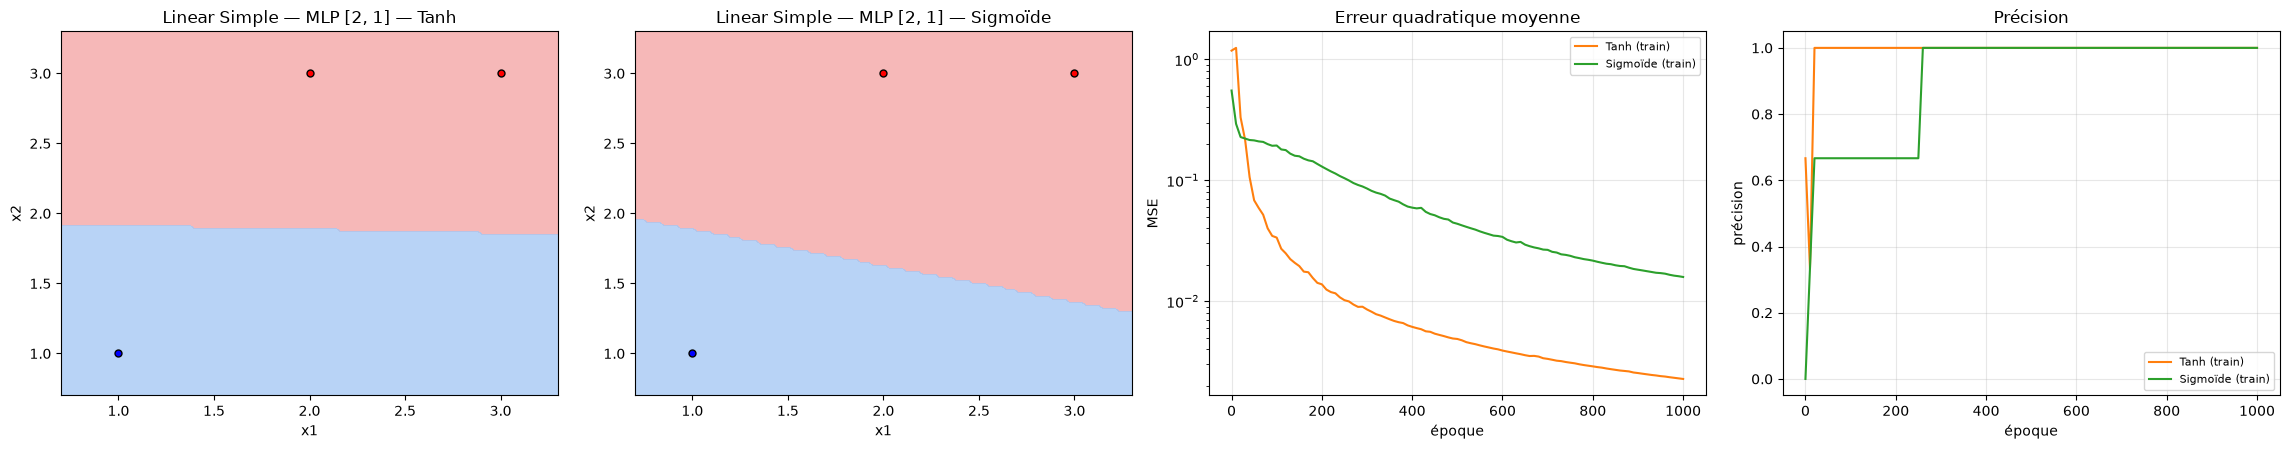

In [3]:
X = np.array([[1, 1], [2, 3], [3, 3]])
Y = np.array([1, -1, -1])

modeles, hists = etude_classification("Linear Simple", "linear_simple", [2, 1], X, Y,
                                      alpha=0.1, epochs=1000, seed=0, essais=5)

### Linear Multiple
Attendu : Modèle linéaire OK · **MLP (2, 1) : OK**

Tanh      | α = 0.1   | 500 époques | 3 poids | graine 0 (1 essai(s)) | précision train = 100.0% -> OK
Sigmoïde  | α = 0.1   | 500 époques | 3 poids | graine 0 (1 essai(s)) | précision train = 100.0% -> OK


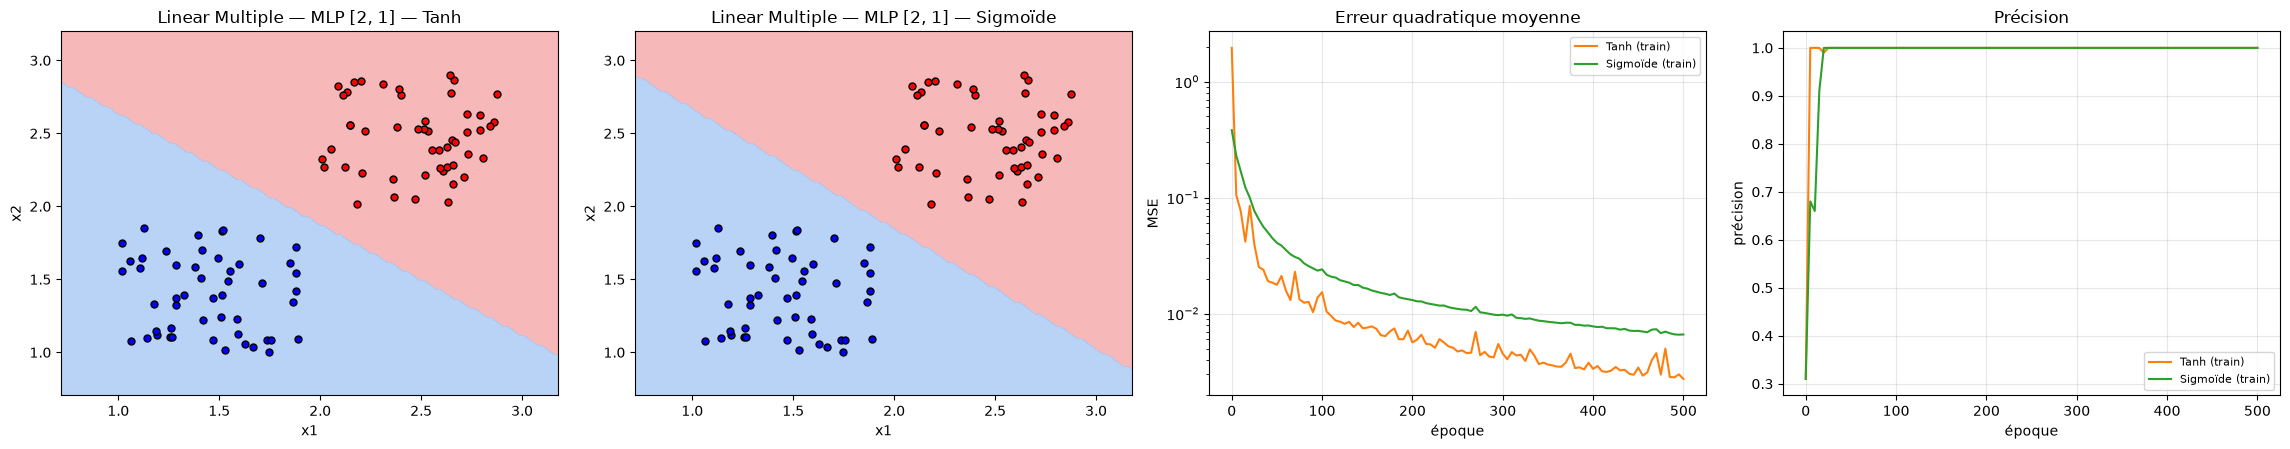

In [4]:
np.random.seed(0)
X = np.concatenate([np.random.random((50, 2)) * 0.9 + np.array([1, 1]), np.random.random((50, 2)) * 0.9 + np.array([2, 2])])
Y = np.concatenate([np.ones((50, 1)), np.ones((50, 1)) * -1.0])

modeles, hists = etude_classification("Linear Multiple", "linear_multiple", [2, 1], X, Y,
                                      alpha=0.1, epochs=500, seed=0, essais=5)

### XOR
Attendu : Modèle linéaire **KO** · **MLP (2, 2, 1) : OK**

Les 4 points du XOR ne sont pas linéairement séparables : il faut une couche cachée. C'est aussi le cas le plus sensible
à l'initialisation des poids (2 neurones cachés seulement) ; on autorise donc jusqu'à 20 essais.

Tanh      | α = 0.3   | 10000 époques | 9 poids | graine 0 (1 essai(s)) | précision train = 100.0% -> OK
Sigmoïde  | α = 0.3   | 10000 époques | 9 poids | graine 0 (1 essai(s)) | précision train = 100.0% -> OK


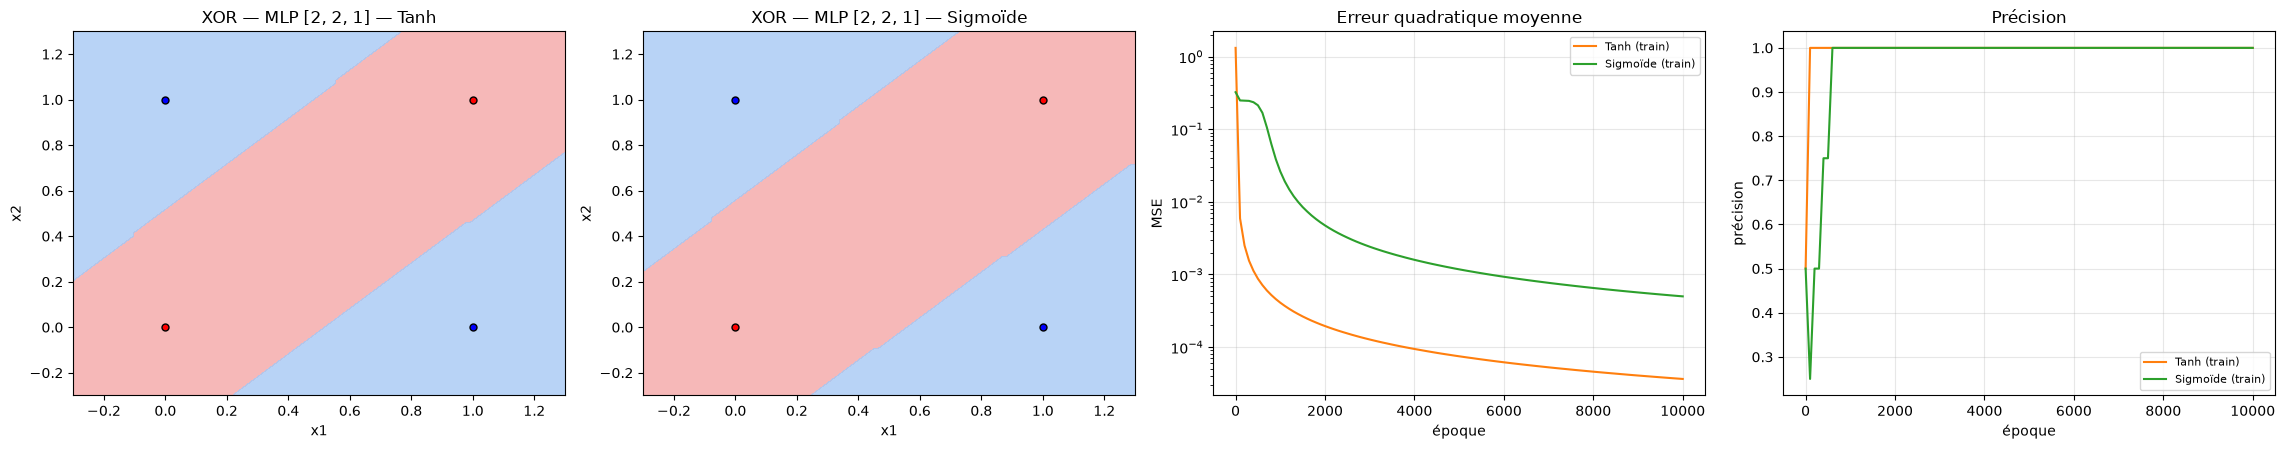

In [5]:
X = np.array([[1, 0], [0, 1], [0, 0], [1, 1]])
Y = np.array([1, 1, -1, -1])

modeles, hists = etude_classification("XOR", "XOR", [2, 2, 1], X, Y,
                                      alpha=0.3, epochs=10000, seed=0, essais=20)

### Cross
Attendu : Modèle linéaire **KO** · **MLP (2, 4, 1) : OK**

On ajoute un jeu de **test** de 200 points neufs (même loi) pour mesurer la généralisation (courbes en pointillés).

Tanh      | α = 0.05  | 4000 époques | 17 poids | graine 0 (1 essai(s)) | précision train = 99.8%, test = 98.5% -> OK
Sigmoïde  | α = 0.05  | 4000 époques | 17 poids | graine 1 (2 essai(s)) | précision train = 99.4%, test = 98.5% -> OK


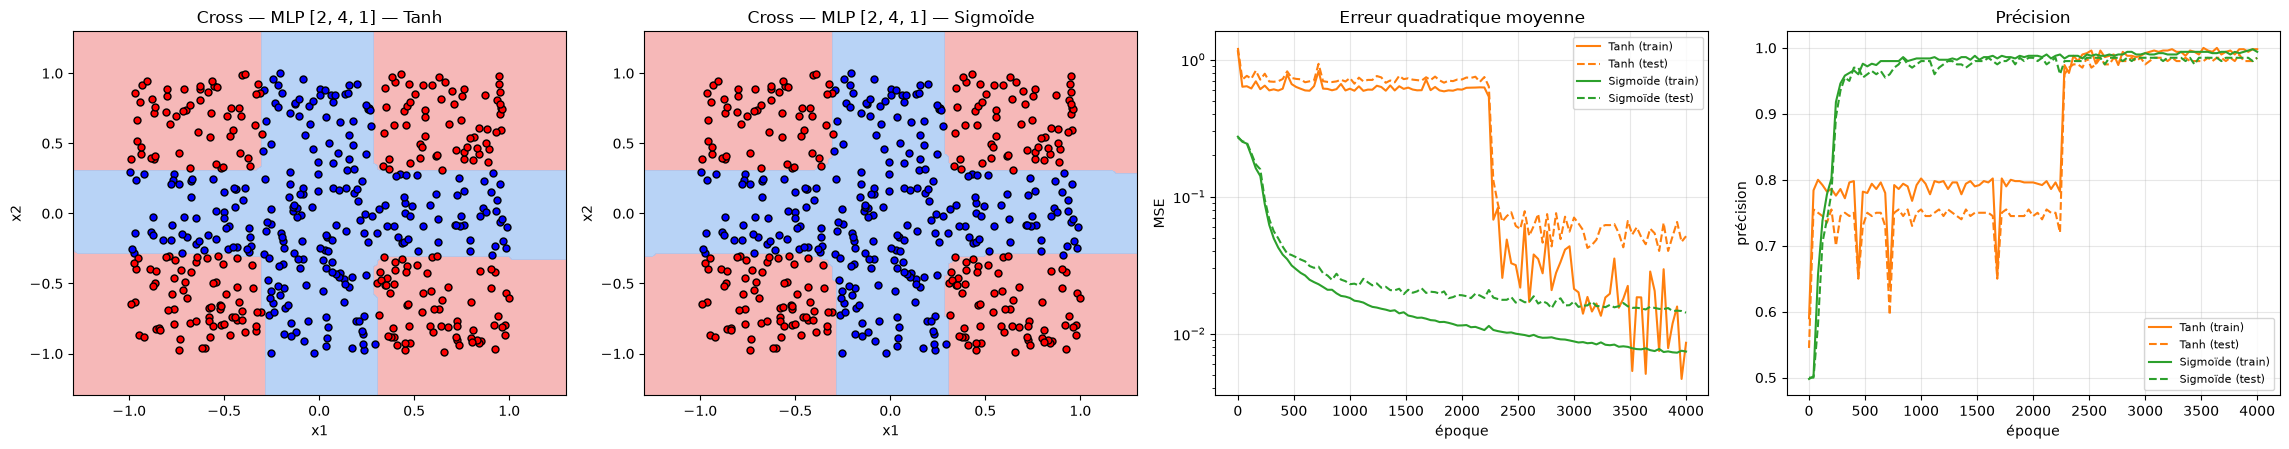

In [6]:
def generer_cross(n):
    X = np.random.random((n, 2)) * 2.0 - 1.0
    Y = np.array([1 if abs(p[0]) <= 0.3 or abs(p[1]) <= 0.3 else -1 for p in X])
    return X, Y

np.random.seed(0)
X, Y = generer_cross(500)
Xt, Yt = generer_cross(200)

modeles, hists = etude_classification("Cross", CROSS_DOSSIER, [2, 4, 1], X, Y,
                                      alpha=0.05, epochs=4000, seed=0, essais=5, seuil=0.98,
                                      test=(Xt, Yt), log_every=40)

### Multi Linear 3 classes
Attendu : Modèle linéaire ×3 OK · **MLP (2, 3) : OK** (une sortie par classe, la plus forte l'emporte)

Tanh      | α = 0.05  | 2000 époques | 9 poids | graine 0 (1 essai(s)) | précision train = 100.0% -> OK
Sigmoïde  | α = 0.05  | 2000 époques | 9 poids | graine 0 (1 essai(s)) | précision train = 100.0% -> OK


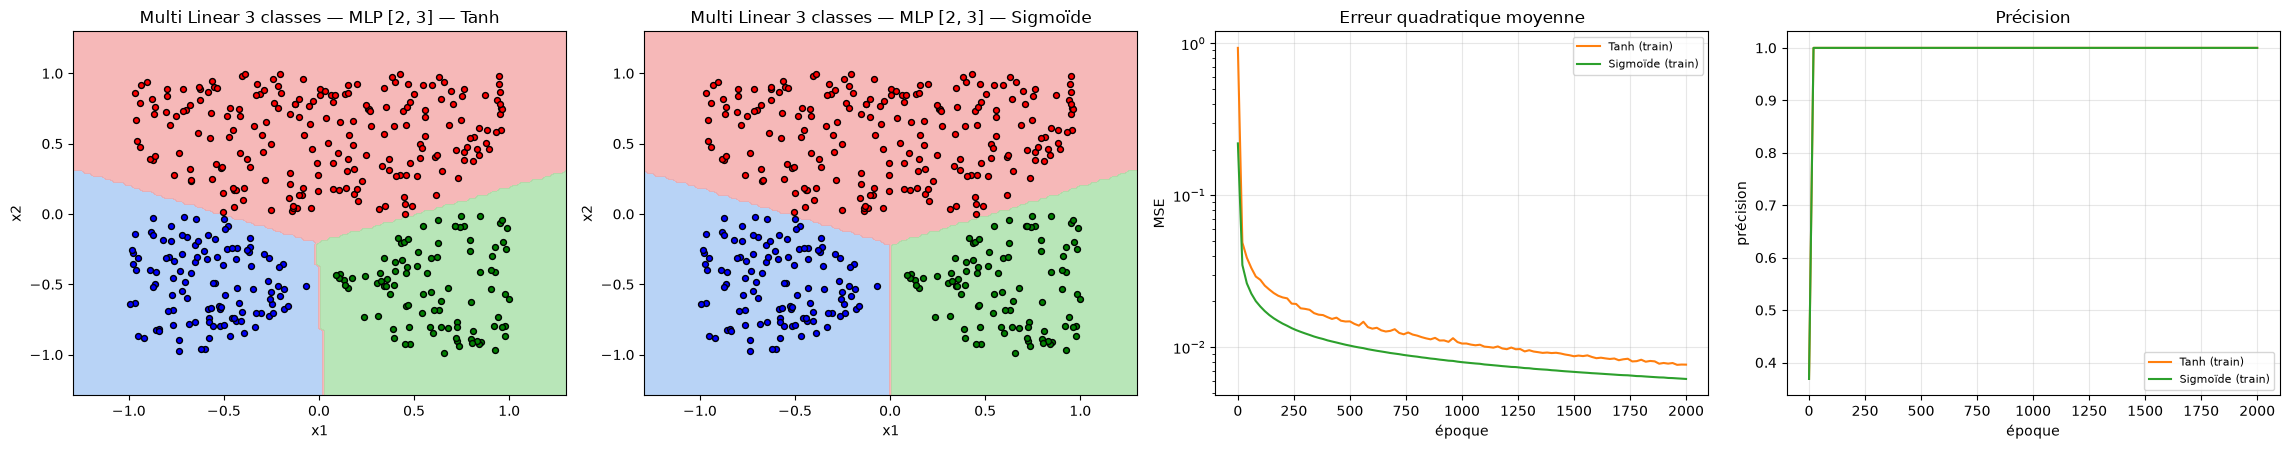

In [7]:
np.random.seed(0)
X = np.random.random((500, 2)) * 2.0 - 1.0
Y = np.array([[1, -1, -1] if -p[0] - p[1] - 0.5 > 0 and p[1] < 0 and p[0] - p[1] - 0.5 < 0 else
              [-1, 1, -1] if -p[0] - p[1] - 0.5 < 0 and p[1] > 0 and p[0] - p[1] - 0.5 < 0 else
              [-1, -1, 1] if -p[0] - p[1] - 0.5 < 0 and p[1] < 0 and p[0] - p[1] - 0.5 > 0 else
              [-1, -1, -1] for p in X])

X = X[[not np.all(arr == [-1, -1, -1]) for arr in Y]]
Y = Y[[not np.all(arr == [-1, -1, -1]) for arr in Y]]

modeles, hists = etude_classification("Multi Linear 3 classes", "multi_linear_3_classes", [2, 3], X, Y,
                                      alpha=0.05, epochs=2000, seed=0, essais=5, seuil=0.98)

### Multi Cross
Attendu : Modèle linéaire ×3 **KO** · **MLP (2, ?, ?, 3) : OK**

Cas le plus difficile : un quadrillage de 64 cases. Les points `?` du notebook sont à choisir ; nous avons retenu
**(2, 32, 32, 3)** (en essayant (2, 16, 16, 3) et (2, 64, 3), voir la section 4 pour l'effet de la taille du réseau).
Les 1000 points sont séparés en **700 pour l'entraînement** et **300 pour le test** afin de mesurer la généralisation.
Critère « OK » : précision d'entraînement ≥ 90 % (le réseau doit apprendre le quadrillage sans que la tâche soit triviale).
La Sigmoïde converge plus lentement que Tanh à α égal : on lui donne un α plus grand (0,1 au lieu de 0,02).

Tanh      | α = 0.02  | 3000 époques | 1251 poids | graine 1 (1 essai(s)) | précision train = 98.7%, test = 90.3% -> OK
Sigmoïde  | α = 0.1   | 3000 époques | 1251 poids | graine 1 (1 essai(s)) | précision train = 96.0%, test = 82.7% -> OK


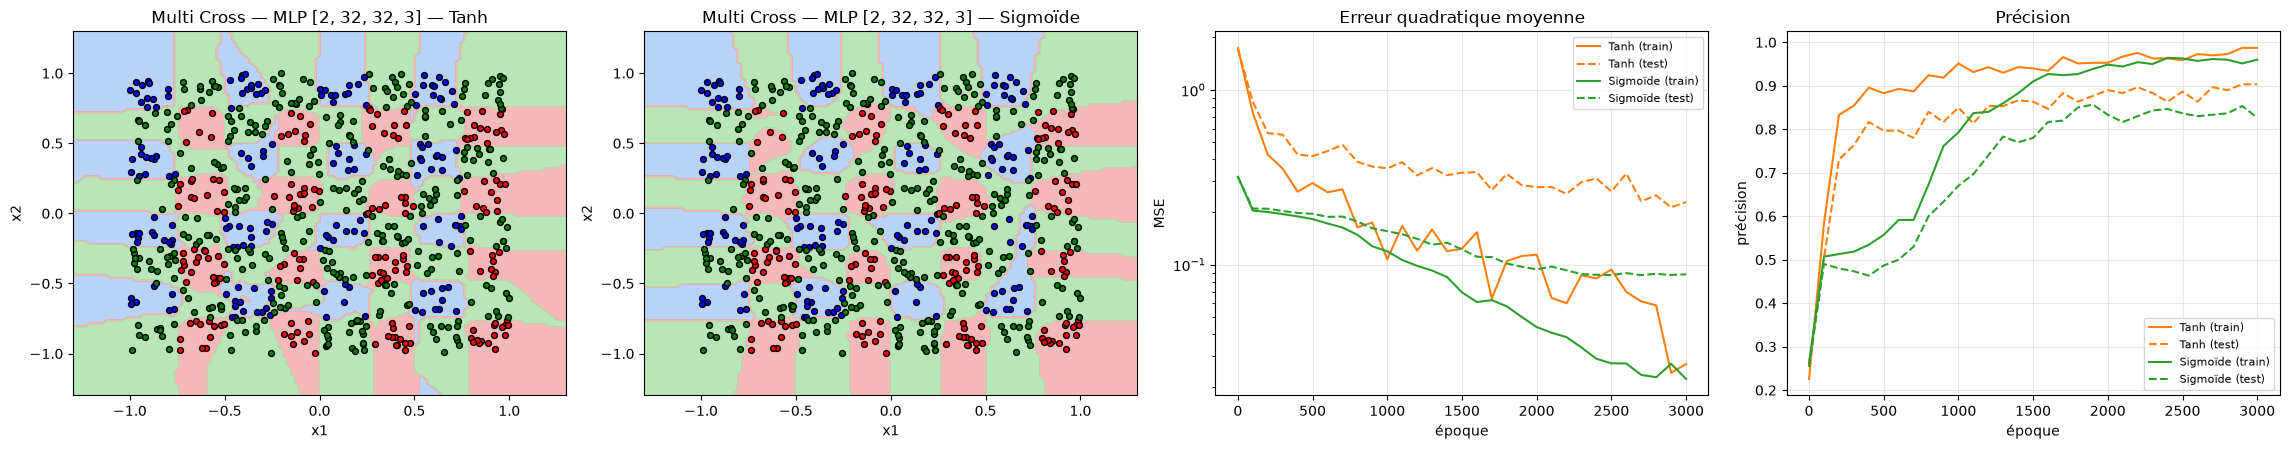

In [8]:
np.random.seed(0)
X = np.random.random((1000, 2)) * 2.0 - 1.0
Y = np.array([[1, -1, -1] if abs(p[0] % 0.5) <= 0.25 and abs(p[1] % 0.5) > 0.25 else
              [-1, 1, -1] if abs(p[0] % 0.5) > 0.25 and abs(p[1] % 0.5) <= 0.25 else
              [-1, -1, 1] for p in X])
Xtr, Ytr, Xte, Yte = X[:700], Y[:700], X[700:], Y[700:]

modeles, hists = etude_classification("Multi Cross", "multi_cross", [2, 32, 32, 3], Xtr, Ytr,
                                      alpha={"tanh": 0.02, "sigmoid": 0.1}, epochs=3000, seed=1, essais=1,
                                      seuil=0.90, test=(Xte, Yte), log_every=100)

## 3. Régression

La couche de sortie est **linéaire** (`δ^L = x^L − y`) ; la fonction d'activation (Tanh ou Sigmoïde) ne s'applique qu'aux couches **cachées**.
Sans couche cachée (architecture `(n, 1)`), l'activation n'intervient donc pas : un seul entraînement est présenté.
Critère « OK » : erreur absolue moyenne sur les exemples < 0,05.

### Linear Simple 2D
Attendu : Modèle linéaire OK · **MLP (1, 1) : OK**

(sans couche cachée : activation sans effet) | α = 0.05  | 2000 époques | 2 poids | graine 0 (1 essai(s)) | erreur absolue moyenne = 0.0000 -> OK


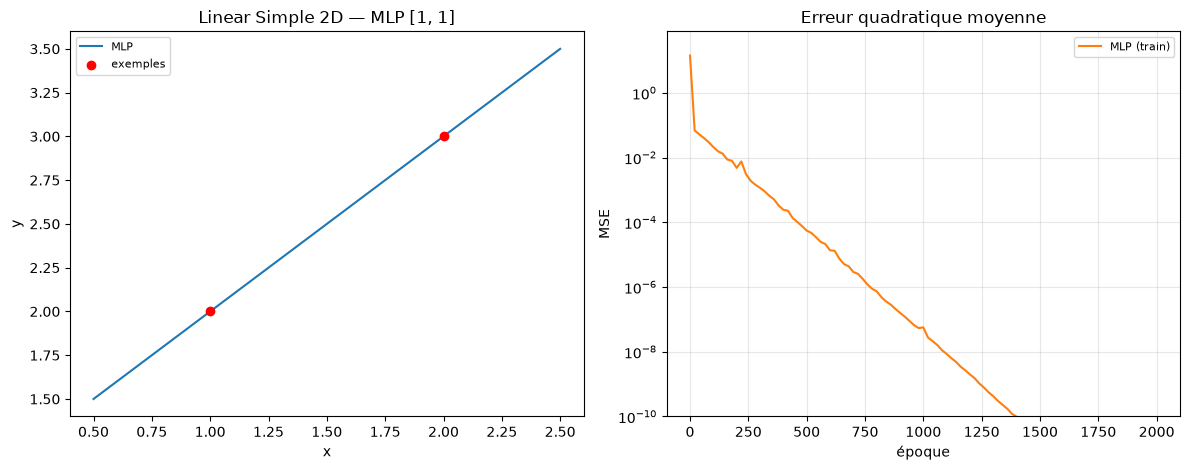

In [9]:
X = np.array([[1], [2]])
Y = np.array([2, 3])

modeles, hists = etude_regression("Linear Simple 2D", "linear_simple_2D", [1, 1], X, Y,
                                  alpha=0.05, epochs=2000, seed=0, essais=3)

### Non Linear Simple 2D
Attendu : Modèle linéaire OK (approximation) · **MLP (1, ?, 1) : OK**

Les 3 points ne sont pas alignés : une droite ne peut pas passer par tous. Nous retenons **4 neurones cachés** (1, 4, 1),
soit 13 poids pour 3 exemples : le réseau peut interpoler exactement les points (voir la section 4 sur le lien entre
nombre de poids et nombre d'exemples). La Sigmoïde reçoit un α plus grand (0,1) car elle converge plus lentement.

Tanh      | α = 0.05  | 10000 époques | 13 poids | graine 0 (1 essai(s)) | erreur absolue moyenne = 0.0000 -> OK
Sigmoïde  | α = 0.1   | 10000 époques | 13 poids | graine 0 (1 essai(s)) | erreur absolue moyenne = 0.0000 -> OK


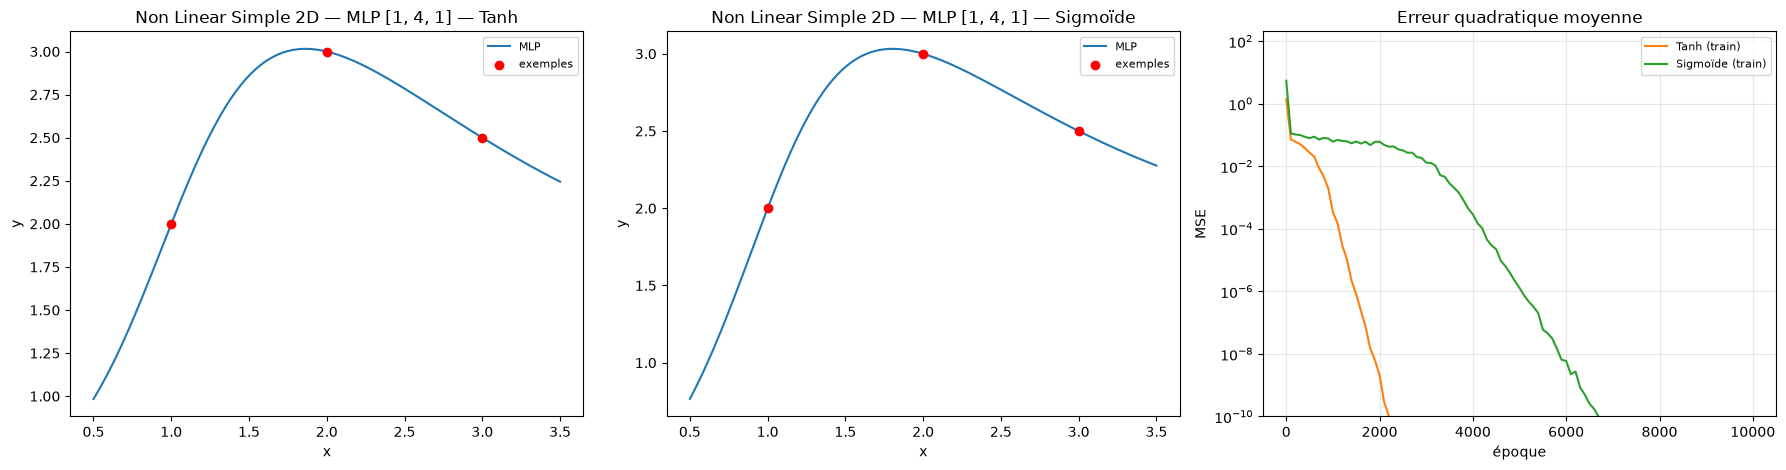

In [10]:
X = np.array([[1], [2], [3]])
Y = np.array([2, 3, 2.5])

modeles, hists = etude_regression("Non Linear Simple 2D", "non_linear_simple_2D", [1, 4, 1], X, Y,
                                  alpha={"tanh": 0.05, "sigmoid": 0.1}, epochs=10000, seed=0, essais=10)

### Linear Simple 3D
Attendu : Modèle linéaire OK · **MLP (2, 1) : OK**

(sans couche cachée : activation sans effet) | α = 0.01  | 3000 époques | 3 poids | graine 0 (1 essai(s)) | erreur absolue moyenne = 0.0024 -> OK


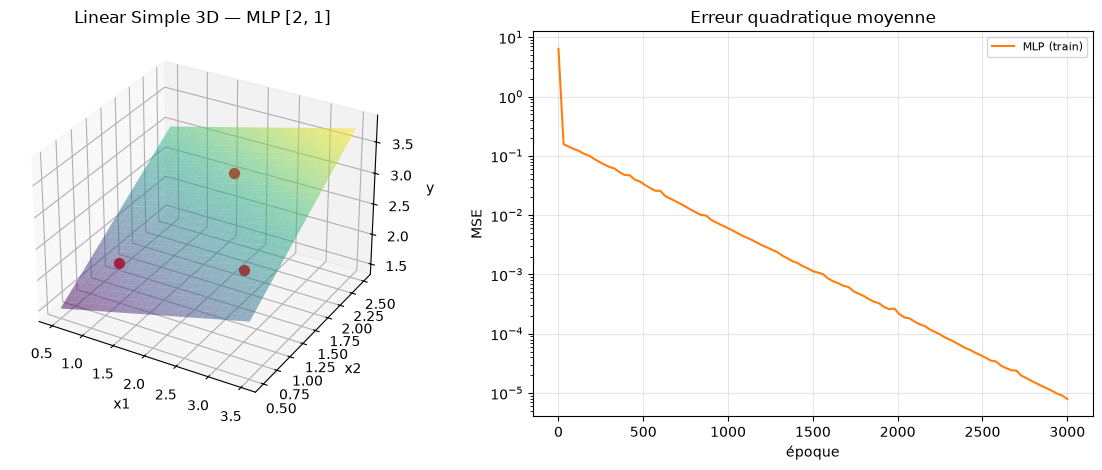

In [11]:
X = np.array([[1, 1], [2, 2], [3, 1]])
Y = np.array([2, 3, 2.5])

modeles, hists = etude_regression("Linear Simple 3D", "linear_simple_3D", [2, 1], X, Y,
                                  alpha=0.01, epochs=3000, seed=0, essais=3)

### Linear Tricky 3D
Attendu : Modèle linéaire OK · **MLP (2, 1) : OK**

Les 3 points sont **alignés sur la diagonale** (x1 = x2) : une infinité de plans passent par eux. La descente de gradient en trouve
un seul (celui qui dépend de l'initialisation) : la surface est donc juste aux points d'entraînement mais arbitraire en dehors de la diagonale.

(sans couche cachée : activation sans effet) | α = 0.01  | 3000 époques | 3 poids | graine 0 (1 essai(s)) | erreur absolue moyenne = 0.0000 -> OK


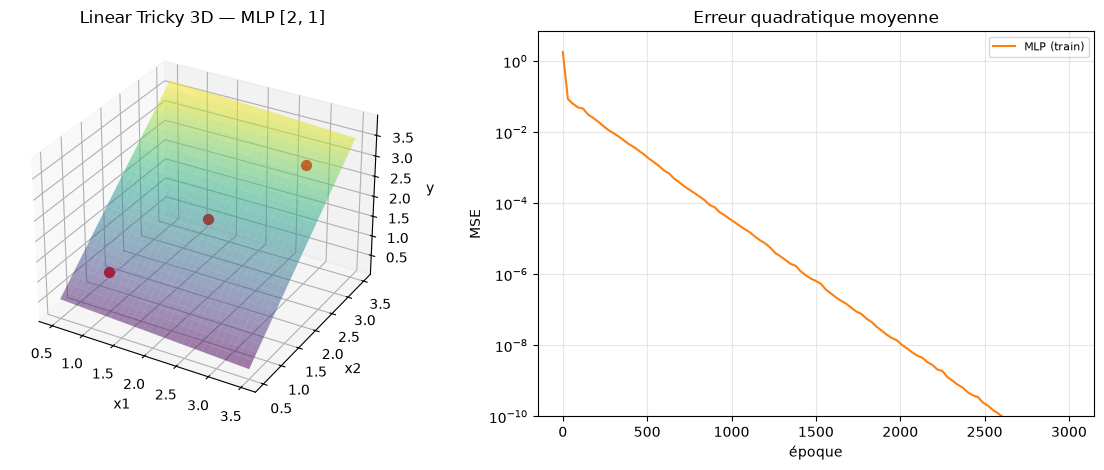

In [12]:
X = np.array([[1, 1], [2, 2], [3, 3]])
Y = np.array([1, 2, 3])

modeles, hists = etude_regression("Linear Tricky 3D", "linear_tricky_3D", [2, 1], X, Y,
                                  alpha=0.01, epochs=3000, seed=0, essais=3)

### Non Linear Simple 3D
Attendu : Modèle linéaire **KO** · **MLP (2, 2, 1) : OK**

4 points dont les valeurs ne sont pas sur un même plan. Comme pour le XOR, 2 neurones cachés suffisent mais l'apprentissage dépend de l'initialisation :
jusqu'à 20 essais autorisés.

Tanh      | α = 0.05  | 10000 époques | 9 poids | graine 0 (1 essai(s)) | erreur absolue moyenne = 0.0000 -> OK
Sigmoïde  | α = 0.05  | 10000 époques | 9 poids | graine 0 (1 essai(s)) | erreur absolue moyenne = 0.0000 -> OK


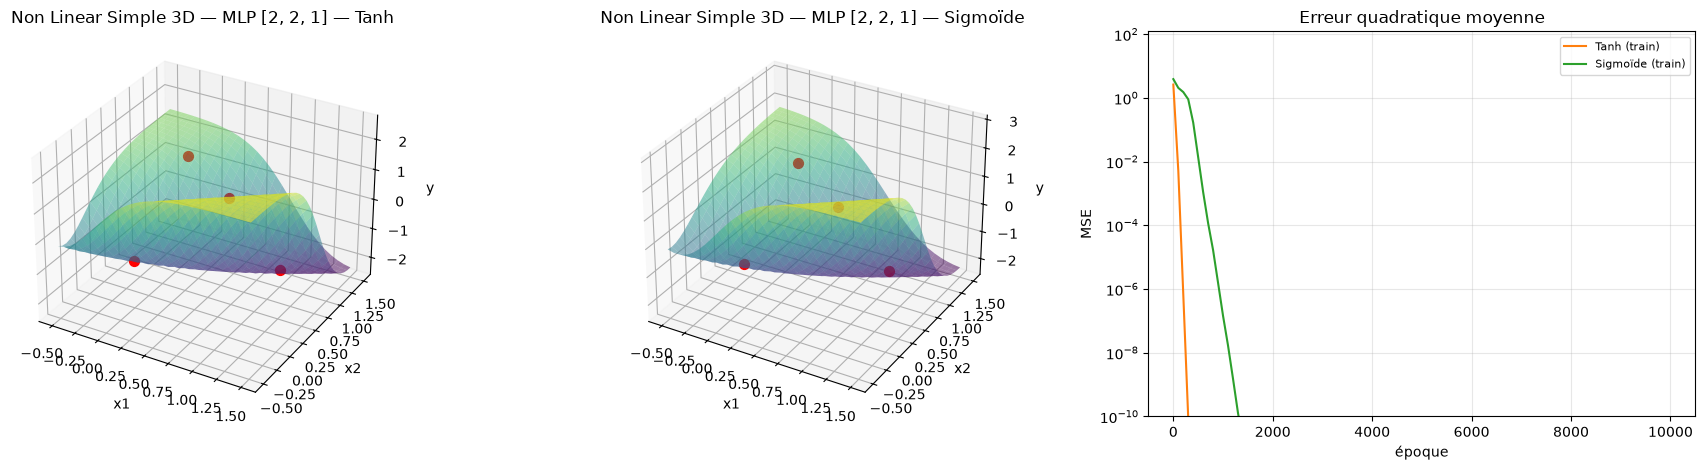

In [13]:
X = np.array([[1, 0], [0, 1], [1, 1], [0, 0]])
Y = np.array([2, 1, -2, -1])

modeles, hists = etude_regression("Non Linear Simple 3D", "non_linear_simple_3D", [2, 2, 1], X, Y,
                                  alpha=0.05, epochs=10000, seed=0, essais=20)

## 4. Impact des paramètres sur la convergence

Le sujet demande d'étudier l'impact des paramètres sur la **rapidité de convergence** et de mettre en évidence le sous-apprentissage,
le sur-apprentissage et la difficulté de choisir un modèle « suffisamment complexe mais suffisamment simple ». Quatre études :
**A.** le pas d'apprentissage α · **B.** le nombre de neurones cachés · **C.** l'initialisation des poids · **D.** le nombre d'exemples face au nombre de poids.
Les figures sont enregistrées dans `results/MLP/etude_parametres/`.

### A. Pas d'apprentissage α (cas Cross, MLP (2, 4, 1))
Même initialisation des poids pour tous les α (même graine), 2000 époques. On mesure le **nombre d'époques nécessaires pour atteindre 95 % de précision**.

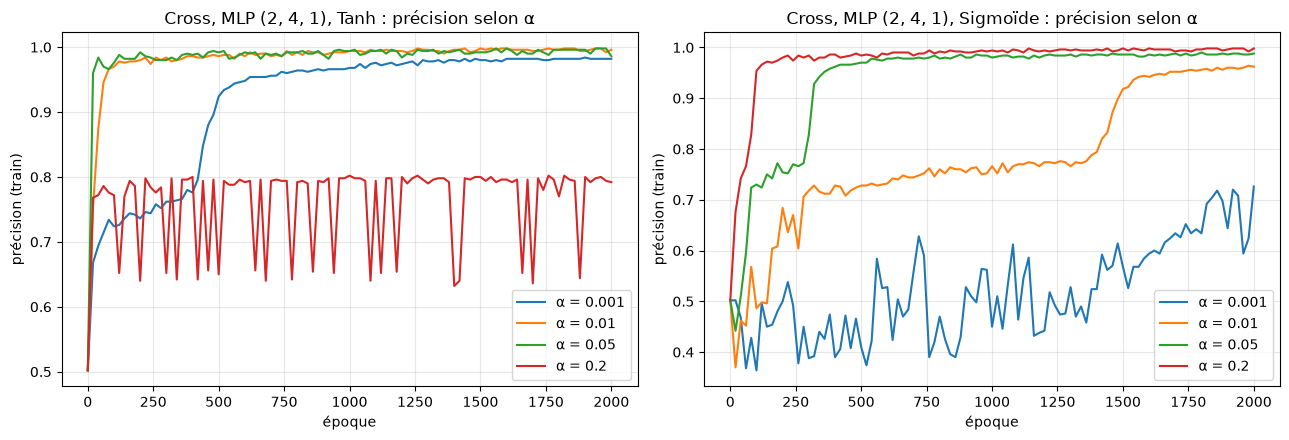

Époques nécessaires pour atteindre 95 % de précision (— = non atteint en 2000 époques)
      α |   Tanh | Sigmoïde
  0.001 |    620 |        —
   0.01 |     80 |     1680
   0.05 |     20 |      360
    0.2 |      — |      100


In [14]:
np.random.seed(0)
Xc, Yc = generer_cross(500)
alphas = [0.001, 0.01, 0.05, 0.2]
EPOCHS = 2000
atteint = {}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for act, ax in zip(("tanh", "sigmoid"), axes):
    for a in alphas:
        m = MLP([2, 4, 1], activation=act, task="classification", seed=3)
        h = m.fit(Xc, Yc, alpha=a, epochs=EPOCHS, log_every=20)
        ax.plot(h["epoch"], h["train_score"], label=f"α = {a}")
        atteint[(act, a)] = next((e for e, s in zip(h["epoch"], h["train_score"]) if s >= 0.95), None)
    ax.set_title(f"Cross, MLP (2, 4, 1), {NOM[act]} : précision selon α")
    ax.set_xlabel("époque"); ax.set_ylabel("précision (train)"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout()
sauver(fig, "etude_parametres", "alpha", "impact_alpha_cross.png")
plt.show()

print("Époques nécessaires pour atteindre 95 % de précision (— = non atteint en", EPOCHS, "époques)")
print(f"{'α':>7s} | {'Tanh':>6s} | {'Sigmoïde':>8s}")
for a in alphas:
    t, s = atteint[("tanh", a)], atteint[("sigmoid", a)]
    print(f"{a:7} | {t if t is not None else '—':>6} | {s if s is not None else '—':>8}")

### B. Nombre de neurones cachés (cas Cross) : sous-apprentissage et complexité du modèle
MLP (2, n, 1) avec n = 1, 2, 4, 8, 16 ; 300 points d'entraînement, 300 points de test neufs ; moyenne sur 2 initialisations.
Trop peu de neurones : le modèle est trop simple et ne peut pas apprendre la croix (**sous-apprentissage**, mauvaise précision même en train).

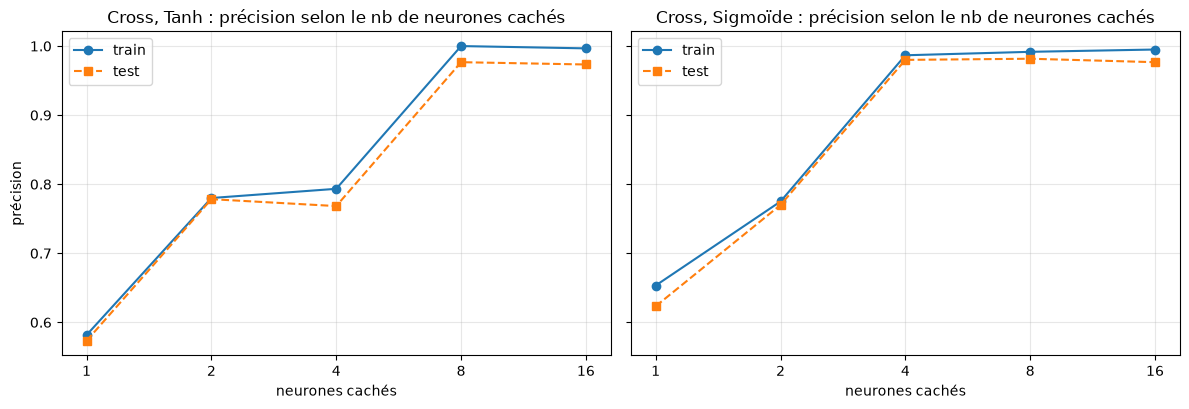

n cachés | nb poids |   Tanh train/test | Sigmoïde train/test
       1 |        5 |   58.2% /  57.3% |     65.3% /  62.3%
       2 |        9 |   78.0% /  77.8% |     77.5% /  77.0%
       4 |       17 |   79.3% /  76.8% |     98.7% /  98.0%
       8 |       33 |  100.0% /  97.7% |     99.2% /  98.2%
      16 |       65 |   99.7% /  97.3% |     99.5% /  97.7%


In [15]:
np.random.seed(0)
Xa, Ya = generer_cross(300)
Xb, Yb = generer_cross(300)
tailles = [1, 2, 4, 8, 16]
res_B = {}

for act in ("tanh", "sigmoid"):
    for n in tailles:
        tr, te = [], []
        for graine in (11, 12):
            m = MLP([2, n, 1], activation=act, task="classification", seed=graine)
            m.fit(Xa, Ya, alpha=0.05, epochs=2000, log_every=2000)
            tr.append(m.score(Xa, Ya)); te.append(m.score(Xb, Yb))
        res_B[(act, n)] = (np.mean(tr), np.mean(te), m.n_weights)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for act, ax in zip(("tanh", "sigmoid"), axes):
    ax.plot(tailles, [res_B[(act, n)][0] for n in tailles], "o-", label="train")
    ax.plot(tailles, [res_B[(act, n)][1] for n in tailles], "s--", label="test")
    ax.set_xscale("log", base=2); ax.set_xticks(tailles); ax.set_xticklabels(tailles)
    ax.set_title(f"Cross, {NOM[act]} : précision selon le nb de neurones cachés")
    ax.set_xlabel("neurones cachés"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("précision")
fig.tight_layout()
sauver(fig, "etude_parametres", "neurones_caches", "impact_neurones_caches_cross.png")
plt.show()

print(f"{'n cachés':>8s} | {'nb poids':>8s} | {'Tanh train/test':>17s} | {'Sigmoïde train/test':>19s}")
for n in tailles:
    t, s = res_B[("tanh", n)], res_B[("sigmoid", n)]
    print(f"{n:8d} | {t[2]:8d} | {t[0]:7.1%} / {t[1]:6.1%} | {s[0]:9.1%} / {s[1]:6.1%}")

### C. Initialisation des poids (cas XOR)
Pour chaque architecture et chaque activation, **30 initialisations différentes** (α = 0,3 ; 10 000 époques). On compte le taux de réussite (précision 100 %).
Sans couche cachée, le XOR est impossible (modèle linéaire KO) ; avec une couche cachée, la réussite dépend de l'initialisation (minimums locaux).

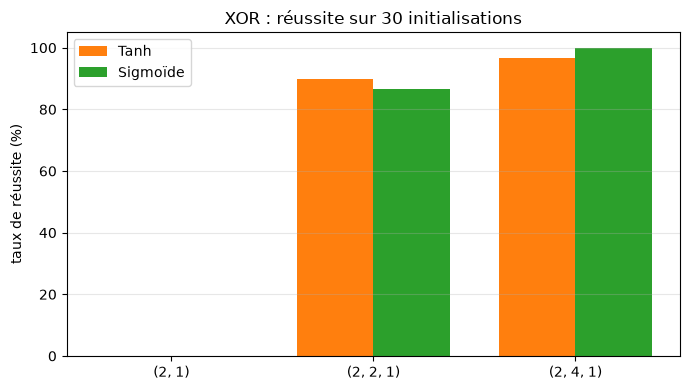

 architecture |   Tanh | Sigmoïde
       (2, 1) |     0% |       0%
    (2, 2, 1) |    90% |      87%
    (2, 4, 1) |    97% |     100%


In [16]:
Xx = np.array([[1, 0], [0, 1], [0, 0], [1, 1]])
Yx = np.array([1, 1, -1, -1])
archis = [[2, 1], [2, 2, 1], [2, 4, 1]]
NB_GRAINES = 30
taux = {}

for layers in archis:
    for act in ("tanh", "sigmoid"):
        reussites = 0
        for graine in range(NB_GRAINES):
            m = MLP(layers, activation=act, task="classification", seed=graine)
            m.fit(Xx, Yx, alpha=0.3, epochs=10000, log_every=10000)
            reussites += m.score(Xx, Yx) == 1.0
        taux[(str(layers), act)] = reussites / NB_GRAINES

fig, ax = plt.subplots(figsize=(7, 4))
largeur = 0.38
pos = np.arange(len(archis))
for k, act in enumerate(("tanh", "sigmoid")):
    ax.bar(pos + (k - 0.5) * largeur, [taux[(str(a), act)] * 100 for a in archis], largeur,
           color=COULEUR[act], label=NOM[act])
ax.set_xticks(pos); ax.set_xticklabels([str(tuple(a)) for a in archis])
ax.set_ylabel("taux de réussite (%)"); ax.set_title(f"XOR : réussite sur {NB_GRAINES} initialisations")
ax.set_ylim(0, 105); ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
sauver(fig, "etude_parametres", "initialisation", "sensibilite_initialisation_xor.png")
plt.show()

print(f"{'architecture':>13s} | {'Tanh':>6s} | {'Sigmoïde':>8s}")
for a in archis:
    print(f"{str(tuple(a)):>13s} | {taux[(str(a), 'tanh')]:6.0%} | {taux[(str(a), 'sigmoid')]:8.0%}")

### D. Nombre d'exemples face au nombre de poids (règle du cours, slide 58)
Règle approximative du cours : ne pas espérer une bonne généralisation si le nombre d'exemples n'est pas supérieur à **10 fois** le nombre de paramètres.
Les cas de tests à quelques points valident l'**implémentation**, mais pas la capacité de généralisation ; le tableau ci-dessous le montre.

## 5. Synthèse des cas de tests

In [17]:
import csv

print(f"{'Cas':24s} {'Archi':16s} {'Activation':10s} {'Résultat':>14s} {'Test':>7s} {'Verdict':>7s} {'Poids':>6s} {'Exemples':>8s} {'Exemples/poids':>14s}")
print("-" * 118)
lignes = []
for (cat, cas, archi, act, score, score_te, verdict, n_poids, n_ex) in RESUME:
    res = f"{score:.1%}" if cat == "classification" else f"MAE {score:.4f}"
    te = f"{score_te:.1%}" if score_te is not None else ""
    ratio = n_ex / n_poids
    print(f"{cas:24s} {archi:16s} {act:10s} {res:>14s} {te:>7s} {verdict:>7s} {n_poids:6d} {n_ex:8d} {ratio:14.1f}" + ("" if ratio >= 10 else "  < 10"))
    lignes.append([cat, cas, archi, act, res, te, verdict, n_poids, n_ex, round(ratio, 2)])

os.makedirs(RESULTS, exist_ok=True)
with open(os.path.join(RESULTS, "resume_cas_de_tests.csv"), "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["categorie", "cas", "architecture", "activation", "resultat", "test", "verdict", "nb_poids", "nb_exemples", "exemples_par_poids"])
    w.writerows(lignes)
print("\nRésumé enregistré dans", os.path.join(RESULTS, "resume_cas_de_tests.csv"))

Cas                      Archi            Activation       Résultat    Test Verdict  Poids Exemples Exemples/poids
----------------------------------------------------------------------------------------------------------------------
Linear Simple            [2, 1]           Tanh               100.0%              OK      3        3            1.0  < 10
Linear Simple            [2, 1]           Sigmoïde           100.0%              OK      3        3            1.0  < 10
Linear Multiple          [2, 1]           Tanh               100.0%              OK      3      100           33.3
Linear Multiple          [2, 1]           Sigmoïde           100.0%              OK      3      100           33.3
XOR                      [2, 2, 1]        Tanh               100.0%              OK      9        4            0.4  < 10
XOR                      [2, 2, 1]        Sigmoïde           100.0%              OK      9        4            0.4  < 10
Cross                    [2, 4, 1]        Tanh      

## 6. Analyse critique (cas de tests)

Les valeurs exactes dépendent du générateur aléatoire de la machine (`rand()` diffère selon le système et le compilateur) ; les tendances ci-dessous
sont celles observées dans nos exécutions et se retrouvent d'une exécution à l'autre.

1. **L'implémentation est validée.** Les 11 cas atteignent leur critère avec Tanh et Sigmoïde (voir le tableau de synthèse). Les cas à quelques points ne valident que le calcul (forward et rétropropagation), pas la généralisation.
2. **Le MLP dépasse le modèle linéaire grâce à la couche cachée.** Sans couche cachée, le XOR n'est jamais appris (taux de réussite nul sur 30 initialisations, étude C). Sur Cross, 1 ou 2 neurones cachés donnent un **sous-apprentissage** (précision faible même sur les données d'entraînement) ; à partir de 4 neurones avec Tanh (8 avec la Sigmoïde, qui converge plus lentement) le réseau apprend la croix (étude B).
3. **Tanh et Sigmoïde ne se comportent pas pareil.** À α égal, la Sigmoïde converge plus lentement : il lui faut un α plus grand (étude A), et elle montre un long plateau avant de « décrocher » sur le XOR. Dans nos essais, elle a toutefois réussi plus souvent que Tanh sur le XOR (2, 2, 1) (étude C). Attention : l'erreur quadratique n'est pas comparable d'une activation à l'autre (étiquettes dans {-1, 1} pour Tanh, {0, 1} pour la Sigmoïde) ; on compare donc surtout les **précisions**.
4. **Le pas d'apprentissage α doit être réglé.** Trop petit, la convergence est très lente ; trop grand (α = 0,2 avec Tanh), l'apprentissage devient instable et la précision oscille (étude A).
5. **L'initialisation des poids compte.** Le XOR (2, 2, 1) échoue parfois selon l'initialisation (minimum local) ; avec 4 neurones cachés il a réussi sur les 30 initialisations testées (étude C). D'où les relances avec une autre graine, affichées dans les résultats.
6. **Généralisation et sur-apprentissage.** Sur Multi Cross, le réseau (1251 poids pour 700 exemples, soit bien moins que les 10 exemples par poids du cours) apprend très bien l'entraînement mais généralise nettement moins bien sur le test : écart entre les courbes pleines et pointillées. Plus le réseau est complexe, plus il faut d'exemples (tableau de la section 5).
7. **Cas dégénéré (Linear Tricky 3D).** Les points étant alignés, il existe une infinité de plans solutions : le résultat dépend de l'initialisation et n'est pas fiable en dehors de la diagonale.

**Suite :** la **Partie B** ci-dessous applique le même MLP au dataset réel (images de fleurs), avec Tanh et Sigmoïde, contrôle qualité des données, courbes train/test et étude du sur-apprentissage.

# Partie B — MLP sur le dataset réel (classification d'images de fleurs)

Application visée : reconnaître, à partir d'une photo, la fleur parmi les classes du dataset (`dataset/<classe>/train/` et `dataset/<classe>/test/`, ou `dataset/train/<classe>/` et `dataset/test/<classe>/`).
Nous appliquons le **même MLP** (C++) que dans les cas de tests, avec **Tanh** puis **Sigmoïde**, forward pass **et** rétropropagation.

**Protocole (pour ne pas se tromper soi-même).**
1. **Contrôle qualité** du dataset avant tout apprentissage (tailles, doublons, équilibre des classes).
2. Les **hyperparamètres** (taille d'image, neurones cachés, α) sont choisis sur un jeu de **validation** prélevé dans le train.
3. Le jeu de **test** n'est utilisé qu'à la fin, pour mesurer le résultat des modèles retenus.
4. On regarde les résultats **classe par classe** (matrice de confusion), pas seulement la précision globale.

Toute cette partie est indépendante des données : pour utiliser un autre dataset (une des deux organisations ci-dessus), il suffit de changer `DATASET_DIR`.

## 7. Le dataset

Dataset : /Users/nadinezrg/Desktop/PA/dataset | organisation : classe/split
Classes : ['jasmin', 'jonquille', 'sunflower']

classe        train   test
jasmin         1456    364
jonquille       839    210
sunflower       882    221
total          3177    795


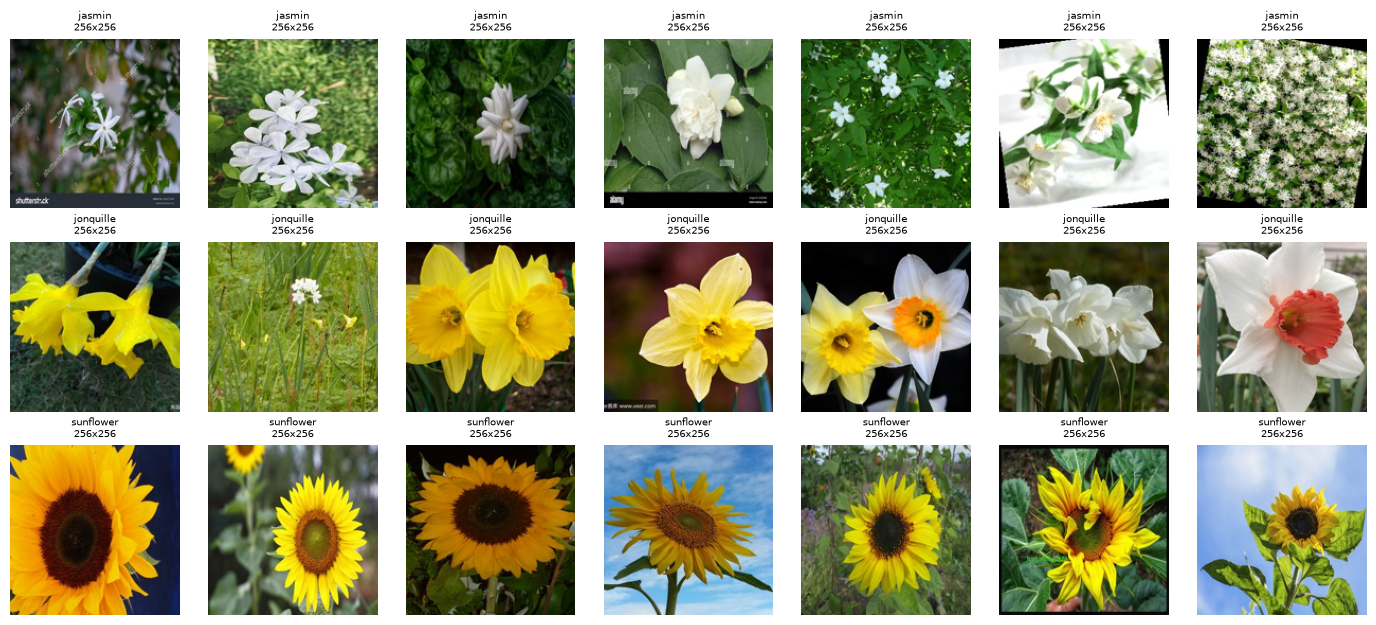

In [18]:
import images_utils as iu
from collections import Counter

DATASET_DIR = None   # <- chemin du dataset si besoin (dossier racine). Organisation reconnue : <classe>/train + <classe>/test, OU train/<classe> + test/<classe>
MODE_RAPIDE = False  # True : grilles et nombre d'époques réduits pour TESTER le notebook vite (résultats moins précis, pas pour le rapport)

def dataset_utilisable(d):
    """Vrai si d est un dataset reconnu (une des 2 organisations) avec au moins une classe contenant des images."""
    return iu.organisation(d) is not None and len(iu.lister_classes_dataset(d)) > 0

if DATASET_DIR is None:
    for cand in ["../dataset", "dataset", "../../dataset"]:
        if dataset_utilisable(cand):
            DATASET_DIR = cand
            break
if DATASET_DIR is None or not dataset_utilisable(DATASET_DIR):
    raise FileNotFoundError("Dataset introuvable, vide, ou organisation non reconnue. Attendu : <dataset>/<classe>/train/ et "
                            "<dataset>/<classe>/test/ (ou <dataset>/train/<classe>/ et <dataset>/test/<classe>/). "
                            "Renseigne DATASET_DIR avec le chemin de la racine du dataset.")

CLASSES = iu.lister_classes_dataset(DATASET_DIR)
K = len(CLASSES)
RES_DS = "dataset_reel"   # sous-dossier de results/MLP
print("Dataset :", os.path.abspath(DATASET_DIR), "| organisation :", iu.organisation(DATASET_DIR))
print("Classes :", CLASSES)

# chargement en 32x32 (sert aux contrôles qualité) + tailles d'origine + chemins
X32_tr, y_tr, chemins_tr, tailles_tr = iu.charger_dataset(DATASET_DIR, "train", CLASSES, 32)
X32_te, y_te, chemins_te, tailles_te = iu.charger_dataset(DATASET_DIR, "test", CLASSES, 32)

print(f"\n{'classe':12s} {'train':>6s} {'test':>6s}")
for c, nom in enumerate(CLASSES):
    print(f"{nom:12s} {np.sum(y_tr == c):6d} {np.sum(y_te == c):6d}")
print(f"{'total':12s} {len(y_tr):6d} {len(y_te):6d}")

# planche d'exemples
from PIL import Image
fig, axes = plt.subplots(K, 7, figsize=(14, 2.1 * K), squeeze=False)   # squeeze=False : marche aussi avec une seule classe
rng = np.random.default_rng(0)
for c, nom in enumerate(CLASSES):
    choix = rng.choice(np.where(y_tr == c)[0], size=7, replace=False)
    for ax, i in zip(axes[c], choix):
        im = Image.open(chemins_tr[i]).convert("RGB"); w, h = im.size; im.thumbnail((160, 160))
        ax.imshow(im); ax.axis("off"); ax.set_title(f"{nom}\n{w}x{h}", fontsize=7)
fig.tight_layout()
sauver(fig, RES_DS, "qualite", "exemples_par_classe.png")
plt.show()

## 8. Contrôle qualité du dataset (biais de la base d'exemples)

Le sujet demande de mettre en évidence les **biais dans la base d'exemples**. Trois vérifications avant d'entraîner quoi que ce soit.

### 8.1 Les classes viennent-elles de la même source ? (tailles d'origine des images)
Si toutes les images d'une classe ont exactement la même taille d'origine alors que celles des autres classes en ont une autre, la **taille de l'image** (et non la fleur)
permettrait de deviner la classe : c'est un raccourci que le dataset offre à n'importe quel modèle. Après redimensionnement ce raccourci disparaît en grande partie, mais le biais de source reste possible (couleurs, fonds, compression).

In [19]:
print(f"{'classe':12s} {'taille d origine dominante':>27s} {'part des images train':>22s} | règle « taille == dominante » sur le test : précision / rappel")
for c, nom in enumerate(CLASSES):
    tc = [tuple(t) for t in tailles_tr[y_tr == c]]
    dom, n_dom = Counter(tc).most_common(1)[0]
    regle = np.all(tailles_te == np.array(dom), axis=1)
    rappel = regle[y_te == c].mean()
    precision = (y_te[regle] == c).mean() if regle.any() else float("nan")
    print(f"{nom:12s} {str(dom[0]) + 'x' + str(dom[1]):>27s} {n_dom / len(tc):22.0%} | {precision:7.0%} / {rappel:.0%}")

classe        taille d origine dominante  part des images train | règle « taille == dominante » sur le test : précision / rappel
jasmin                           256x256                   100% |     46% / 100%
jonquille                        256x256                   100% |     26% / 100%
sunflower                        256x256                   100% |     28% / 100%


### 8.1b Traces d'augmentation : coins noirs
Une rotation d'image avec remplissage noir laisse des **coins noirs**. Si le dataset a été augmenté ainsi, et surtout si c'est **plus fréquent dans certaines classes**, un modèle peut apprendre « coins noirs = cette classe » au lieu de reconnaître la fleur : une photo prise par un utilisateur n'a pas de coins noirs.
Le critère (4 coins quasi noirs) repère 100 % des images tournées de 5° ou plus et à tort 0 à 2 % des photos normales ; quelques % sont donc normaux (fonds sombres).

classe          train     test   (part des images dont les 4 coins sont quasi noirs)
jasmin          32.1%    30.2%
jonquille        0.6%     0.5%
sunflower        0.7%     0.5%

ATTENTION : les coins noirs sont très inégaux selon les classes (de 1% à 32%). Un modèle peut s'en servir comme raccourci ; son effet est mesuré en 12.3.


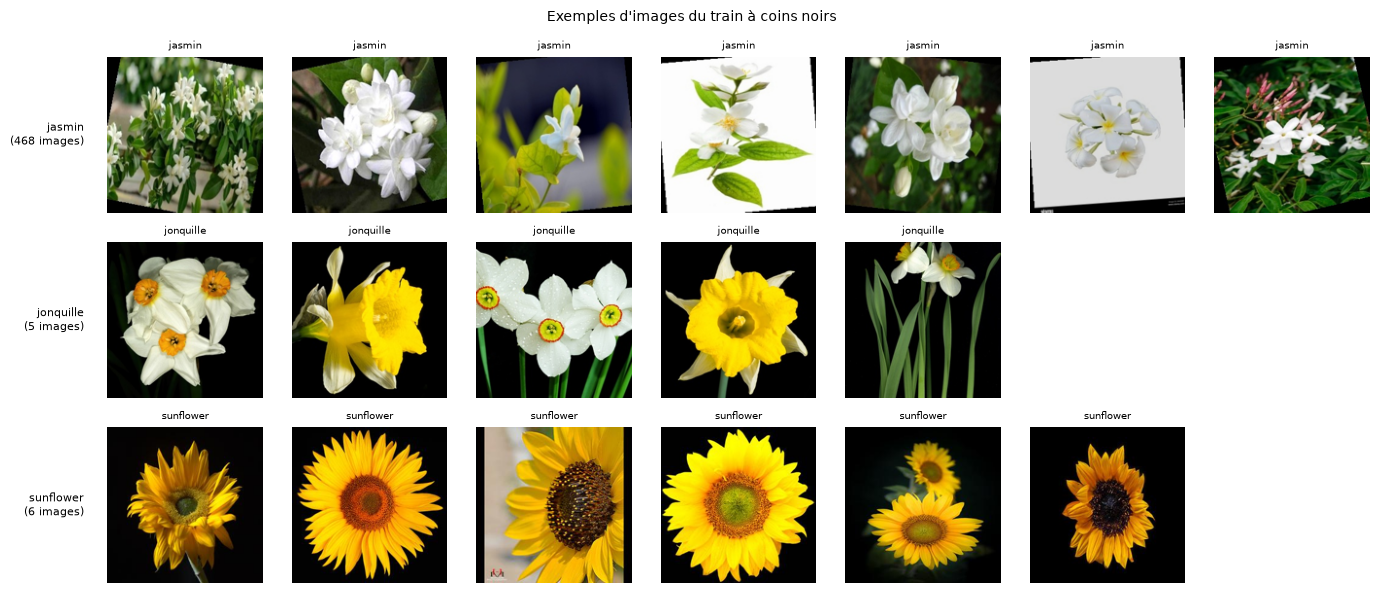

In [20]:
coins_tr = iu.coins_noirs(X32_tr)
coins_te = iu.coins_noirs(X32_te)
print(f"{'classe':12s} {'train':>8s} {'test':>8s}   (part des images dont les 4 coins sont quasi noirs)")
parts = []
for c, nom in enumerate(CLASSES):
    parts.append(coins_tr[y_tr == c].mean())
    print(f"{nom:12s} {coins_tr[y_tr == c].mean():8.1%} {coins_te[y_te == c].mean():8.1%}")
if max(parts) - min(parts) > 0.15:
    print(f"\nATTENTION : les coins noirs sont très inégaux selon les classes (de {min(parts):.0%} à {max(parts):.0%}). "
          "Un modèle peut s'en servir comme raccourci ; son effet est mesuré en 12.3.")
else:
    print("\nPas de différence marquée entre les classes.")

fig, axes = plt.subplots(K, 7, figsize=(14, 2.0 * K))
rng = np.random.default_rng(1)
for c, nom in enumerate(CLASSES):
    ids = np.where(coins_tr & (y_tr == c))[0]
    ids = rng.choice(ids, size=min(7, len(ids)), replace=False) if len(ids) else []
    for ax in axes[c]:
        ax.axis("off")
    for ax, i in zip(axes[c], ids):
        im = Image.open(chemins_tr[i]).convert("RGB"); im.thumbnail((160, 160)); ax.imshow(im)
        ax.set_title(nom, fontsize=7)
    axes[c][0].text(-0.15, 0.5, f"{nom}\n({len(np.where(coins_tr & (y_tr == c))[0])} images)", transform=axes[c][0].transAxes, ha="right", va="center", fontsize=8)
fig.suptitle("Exemples d'images du train à coins noirs", fontsize=10)
fig.tight_layout()
sauver(fig, RES_DS, "qualite", "coins_noirs_exemples.png")
plt.show()

### 8.2 Y a-t-il des doublons ? (fuite entre train et test)
Une image présente à la fois dans le train et dans le test fausse la mesure : le réseau n'a pas besoin de généraliser, il lui suffit de « reconnaître » ce qu'il a déjà vu.
On compare les images (redimensionnées en 32×32) deux à deux : deux images à distance quasi nulle sont les mêmes. Le seuil est choisi dans l'**écart** visible sur l'histogramme (paires quasi identiques d'un côté, images réellement différentes de l'autre).

On compte aussi comme « la même image » une image **retournée en miroir** : si le dataset a été gonflé par **augmentation de données** (images retournées, par exemple), l'original peut être dans le test et sa version retournée dans le train. Ce que cette méthode ne voit pas : les rotations, recadrages et changements de couleur. Si le dataset a été augmenté ainsi, il faut que le découpage train/test ait été fait **avant** l'augmentation.

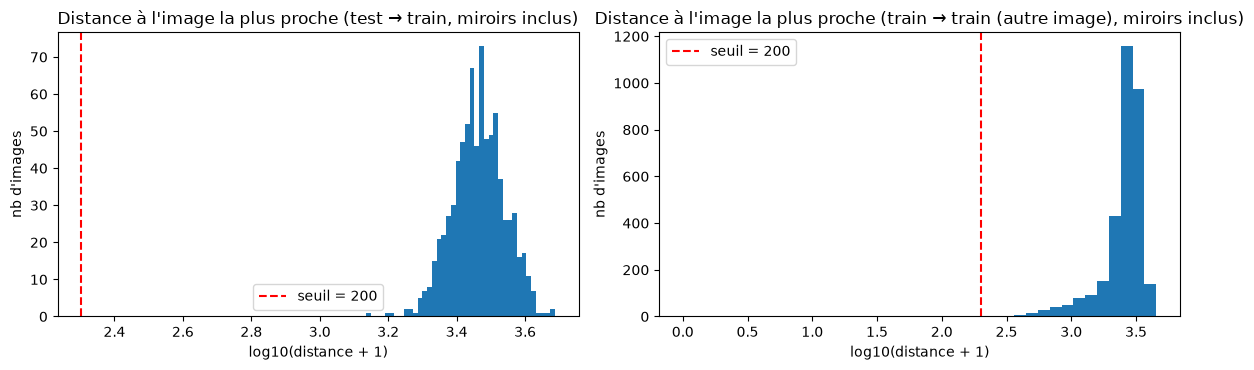

classe          test déjà dans le train  (dont identiques)   train avec doublon dans le train
jasmin                       0 / 364             0                    4 / 1456
jonquille                    0 / 210             0                    0 / 839
sunflower                    0 / 221             0                    4 / 882

Au total : 0 images de test sur 795 (0%) sont déjà dans le train.
-> aucune fuite détectée.


In [21]:
V_tr = X32_tr.reshape(len(X32_tr), -1).astype(np.float32)
V_te = X32_te.reshape(len(X32_te), -1).astype(np.float32)
d_exact_test = iu.distances(V_te, V_tr).min(axis=1)                # test -> train, copie strictement identique seulement
d_min_test = iu.distances_miroirs(X32_te, X32_tr).min(axis=1)      # test -> train, copie identique OU retournée (miroir)
D_tr_tr = iu.distances_miroirs(X32_tr, X32_tr); np.fill_diagonal(D_tr_tr, np.inf)
d_min_train = D_tr_tr.min(axis=1)                                  # train -> une AUTRE image de train (identique ou retournée)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, d, t in zip(ax, (d_min_test, d_min_train), ("test → train, miroirs inclus", "train → train (autre image), miroirs inclus")):
    a.hist(np.log10(d + 1.0), bins=40, color="tab:blue")
    a.axvline(np.log10(iu.SEUIL_DOUBLON + 1.0), color="red", ls="--", label=f"seuil = {iu.SEUIL_DOUBLON:g}")
    a.set_title(f"Distance à l'image la plus proche ({t})"); a.set_xlabel("log10(distance + 1)"); a.set_ylabel("nb d'images"); a.legend()
fig.tight_layout()
sauver(fig, RES_DS, "qualite", "histogramme_doublons.png")
plt.show()

print(f"{'classe':12s} {'test déjà dans le train':>26s} {'(dont identiques)':>18s} {'train avec doublon dans le train':>34s}")
for c, nom in enumerate(CLASSES):
    print(f"{nom:12s} {int((d_min_test[y_te == c] < iu.SEUIL_DOUBLON).sum()):>17d} / {int((y_te == c).sum()):<6d} "
          f"{int((d_exact_test[y_te == c] < iu.SEUIL_DOUBLON).sum()):>10d} {int((d_min_train[y_tr == c] < iu.SEUIL_DOUBLON).sum()):>20d} / {int((y_tr == c).sum())}")
n_fuite = int((d_min_test < iu.SEUIL_DOUBLON).sum())
print(f"\nAu total : {n_fuite} images de test sur {len(y_te)} ({n_fuite / len(y_te):.0%}) sont déjà dans le train.")
if n_fuite / len(y_te) >= 0.02:
    print("-> fuite importante : le test brut est faussé ; les résultats « officiels » seront calculés sur le jeu nettoyé (8.3).")
elif n_fuite > 0:
    print("-> fuite négligeable (moins de 2 % du test) ; ces images sont tout de même retirées du jeu nettoyé (8.3).")
else:
    print("-> aucune fuite détectée.")

### 8.2b Contrôle visuel : les paires test / train les plus proches
La distance ne détecte que les copies quasi identiques (ou retournées). Des copies **tournées, recadrées ou recolorées** lui échappent. On regarde donc **à l'œil** les 6 images de test qui ressemblent le plus à une image du train : si ce sont de simples images voisines, tout va bien ; si ce sont la même fleur légèrement tournée ou recadrée, le test est contaminé.

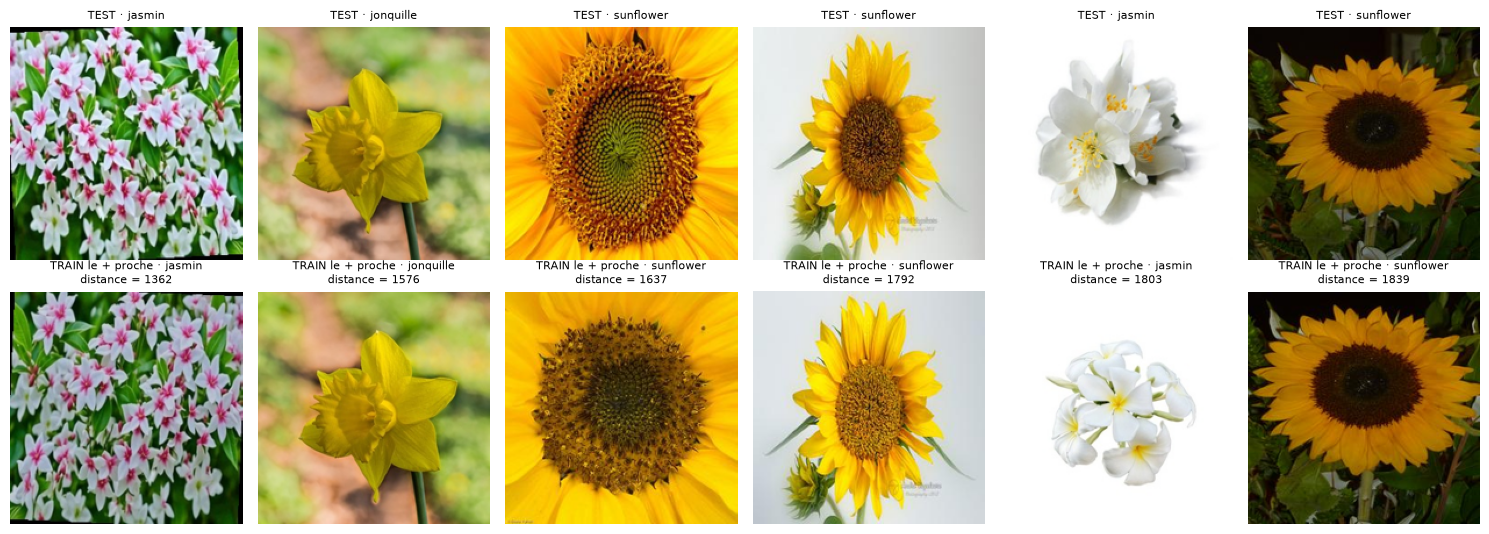

Distances des 6 paires les plus proches : [1361, 1576, 1636, 1792, 1802, 1839] (seuil de doublon = 200, distance typique entre images différentes : plusieurs milliers)


In [22]:
D_mir = iu.distances_miroirs(X32_te, X32_tr)
j_proche, d_proche = D_mir.argmin(axis=1), D_mir.min(axis=1)
ordre = np.argsort(d_proche)[:6]
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for k, i in enumerate(ordre):
    j = j_proche[i]
    for ligne, chemin, titre in ((0, chemins_te[i], f"TEST · {CLASSES[y_te[i]]}"), (1, chemins_tr[j], f"TRAIN le + proche · {CLASSES[y_tr[j]]}\ndistance = {d_proche[i]:.0f}")):
        im = Image.open(chemin).convert("RGB"); im.thumbnail((200, 200))
        axes[ligne, k].imshow(im); axes[ligne, k].axis("off"); axes[ligne, k].set_title(titre, fontsize=8)
fig.tight_layout()
sauver(fig, RES_DS, "qualite", "paires_les_plus_proches.png")
plt.show()
print("Distances des 6 paires les plus proches :", [int(d_proche[i]) for i in ordre], f"(seuil de doublon = {iu.SEUIL_DOUBLON:g}, distance typique entre images différentes : plusieurs milliers)")

### 8.2c Copies TOURNÉES ou retournées (le contrôle précédent ne les voit pas)
La figure 8.2b peut montrer que des images de test ont dans le train une copie légèrement **tournée** ou **retournée** : la distance simple les voit comme différentes (une rotation de quelques degrés l'augmente beaucoup).
On les cherche donc en comparant chaque image de test à ses versions tournées (de -20° à +20°) et retournées, au centre de l'image (pour ignorer les coins noirs). La distance utilisée est un écart quadratique moyen par pixel (échelle 0..255).
**Choix du seuil :** les distances vers la même classe forment une **bosse de vraies copies** (distances faibles), puis une **vallée**, puis la masse des images simplement différentes. On place le seuil dans la vallée (`iu.seuil_copie_auto`), sans jamais dépasser 0,9 x le 1er centile des distances vers des images d'**autres classes** (une copie ne peut pas exister entre deux classes différentes : ces distances montrent ce que valent des images « semblables mais différentes »). Vérifie sur l'histogramme que la ligne rouge est dans la vallée ; sinon, fixe `SEUIL_COPIE` à la main. Le tableau de sensibilité doit montrer un nombre d'images à peu près stable autour du seuil.

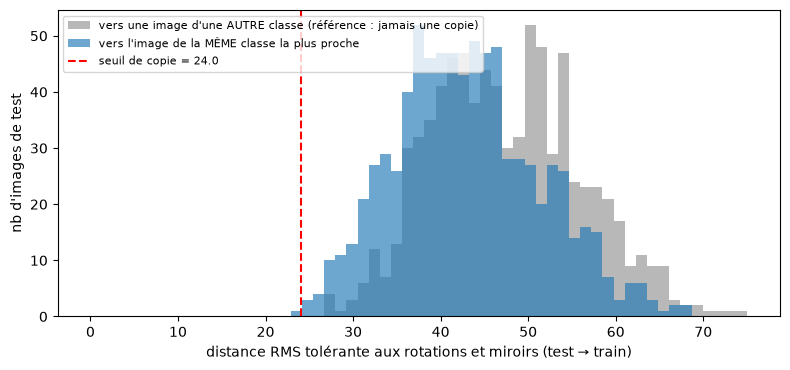

Seuil de copie : 24.0 (vallée de l'histogramme ; 1er centile des distances vers d'autres classes : 30.8)

classe          test avec une copie (tournée / retournée) dans le train
jasmin                                    0 / 364    (0%)
jonquille                                 0 / 210    (0%)
sunflower                                 0 / 221    (0%)

Au total : 0 images de test sur 795 (0%) ont une copie dans le train.
Sensibilité au seuil (nb d'images de test avec copie) : {'x0.5': 0, 'x0.75': 0, 'x1.0': 0, 'x1.5': 154} -> un nombre stable = seuil bien placé dans le vide
Contamination faible.


In [23]:
SEUIL_COPIE = 24.0  # None : calcul automatique (voir ci-dessus) ; sinon un nombre pour le fixer à la main

d_meme_te, d_autre_te = iu.plus_proches_tolerants(X32_te, y_te, X32_tr, y_tr)
p1 = float(np.percentile(d_autre_te, 1))
if SEUIL_COPIE is None:
    SEUIL_COPIE = iu.seuil_copie_auto(d_meme_te, d_autre_te)
copie_te = d_meme_te < SEUIL_COPIE

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(0, max(d_autre_te.max(), d_meme_te.max()) + 1, 60)
ax.hist(d_autre_te, bins=bins, alpha=0.55, label="vers une image d'une AUTRE classe (référence : jamais une copie)", color="tab:gray")
ax.hist(d_meme_te, bins=bins, alpha=0.65, label="vers l'image de la MÊME classe la plus proche", color="tab:blue")
ax.axvline(SEUIL_COPIE, color="red", ls="--", label=f"seuil de copie = {SEUIL_COPIE:.1f}")
ax.set_xlabel("distance RMS tolérante aux rotations et miroirs (test → train)"); ax.set_ylabel("nb d'images de test"); ax.legend(fontsize=8)
fig.tight_layout()
sauver(fig, RES_DS, "qualite", "copies_tournees_histogramme.png")
plt.show()

print(f"Seuil de copie : {SEUIL_COPIE:.1f} (vallée de l'histogramme ; 1er centile des distances vers d'autres classes : {p1:.1f})")
print(f"\n{'classe':12s} {'test avec une copie (tournée / retournée) dans le train':>58s}")
for c, nom in enumerate(CLASSES):
    print(f"{nom:12s} {int(copie_te[y_te == c].sum()):>30d} / {int((y_te == c).sum()):<6d} ({copie_te[y_te == c].mean():.0%})")
n_copie = int(copie_te.sum())
print(f"\nAu total : {n_copie} images de test sur {len(y_te)} ({n_copie / len(y_te):.0%}) ont une copie dans le train.")
print("Sensibilité au seuil (nb d'images de test avec copie) :", {f"x{f}": int((d_meme_te < f * SEUIL_COPIE).sum()) for f in (0.5, 0.75, 1.0, 1.5)}, "-> un nombre stable = seuil bien placé dans le vide")
if n_copie / len(y_te) >= 0.02:
    print("ATTENTION : le test est CONTAMINÉ par des copies tournées/retournées : la précision mesurée sur le test brut est trop optimiste. "
          "Les résultats « officiels » sont calculés sur le test strict (8.3).")
else:
    print("Contamination faible.")

### 8.3 Jeu nettoyé
On retire du **train** les copies multiples d'une même image (retournées comprises), et du **test** les copies multiples, toute image déjà présente dans le train, et toute image dont une copie **tournée ou retournée** (8.2c) est dans le train : c'est le **test strict**.
Les copies tournées restent dans le train (c'est de l'augmentation de données légitime), mais la validation (section 9) est construite **par groupes de copies** : une image et ses copies vont ensemble dans l'apprentissage ou dans la validation, jamais séparées (sinon la validation serait trop optimiste).
Les résultats « officiels » de cette partie sont calculés sur ces jeux nettoyés (test strict) ; la section 12 chiffre ce que la fuite aurait fait croire.

In [24]:
idx_tr, idx_te = iu.nettoyer_train_test(X32_tr, X32_te)
n_avant = len(idx_te)
idx_te = idx_te[~copie_te[idx_te]]          # test strict : on retire aussi les images dont une copie tournée / retournée est dans le train
print(f"Test : {n_avant - len(idx_te)} images supplémentaires retirées car une copie tournée ou retournée est dans le train (8.2c).\n")
y_tr_c, y_te_c = y_tr[idx_tr], y_te[idx_te]

print(f"{'classe':12s} {'train brut':>11s} {'train propre':>13s} | {'test brut':>10s} {'test strict':>12s}")
for c, nom in enumerate(CLASSES):
    print(f"{nom:12s} {int((y_tr == c).sum()):11d} {int((y_tr_c == c).sum()):13d} | {int((y_te == c).sum()):10d} {int((y_te_c == c).sum()):12d}")
print(f"{'total':12s} {len(y_tr):11d} {len(y_tr_c):13d} | {len(y_te):10d} {len(y_te_c):12d}")

part_gardee = len(y_tr_c) / len(y_tr)
if part_gardee < 0.8:
    print(f"\nATTENTION : seules {part_gardee:.0%} des images du train sont distinctes. Le dataset semble contenir beaucoup de copies "
          "(augmentation de données ?) : le nombre d'images distinctes réel est celui de la colonne « train propre ».")

ratio = np.bincount(y_tr_c).min() / np.bincount(y_tr_c).max()
print(f"\nÉquilibre des classes dans le train propre : plus petite / plus grande = {ratio:.2f}")
if ratio < 0.5:
    print("ATTENTION : classes très déséquilibrées -> la précision globale peut cacher qu'une classe n'est jamais reconnue (voir section 11).")

Test : 0 images supplémentaires retirées car une copie tournée ou retournée est dans le train (8.2c).

classe        train brut  train propre |  test brut  test strict
jasmin              1456          1454 |        364          363
jonquille            839           839 |        210          208
sunflower            882           880 |        221          221
total               3177          3173 |        795          792

Équilibre des classes dans le train propre : plus petite / plus grande = 0.58


## 9. Prétraitement et taille du modèle

Chaque image est redimensionnée en `t × t` pixels RGB (`t = 8, 16, 32`), aplatie en un vecteur de `3·t²` entrées, et les pixels (0..255) sont recentrés dans [-1, 1].
Les étiquettes sont en « un seul +1 » : `[1, -1, -1]` pour la classe 0, etc. (une sortie par classe, la plus forte l'emporte, comme pour le cas *Multi Linear 3 classes*).
Le même code (`images_utils.preprocess_image`) sera utilisé par l'application.

**Taille du modèle face au nombre d'exemples (slide 58 : il faudrait ≥ 10 exemples par poids).** Un MLP `(3·t², H, K)` a `(3·t² + 1)·H + (H + 1)·K` poids.

In [25]:
if K < 2:
    raise RuntimeError(
        f"Une seule classe contient des images ({CLASSES}) : le contrôle qualité (sections 7 et 8) est terminé, "
        "mais on ne peut pas entraîner un classifieur avec une seule classe. "
        "Reprends à partir de cette section quand les autres classes seront prêtes.")

TAILLES = (8, 16) if MODE_RAPIDE else (8, 16, 32)
HIDDEN = (4, 16) if MODE_RAPIDE else (4, 16, 32)
n_train = len(y_tr_c)

# Nombre d'époques : une époque = n_train mises à jour de poids. On garde à peu près le même nombre TOTAL de mises à jour
# (époques x exemples) quelle que soit la taille du dataset : avec 10 fois plus d'images, 10 fois moins d'époques suffisent.
MAJ = 26000 if MODE_RAPIDE else 66000
EPOCHS_FINAL = max(5, round(MAJ / n_train))                          # modèle final et études de α
EPOCHS_GRILLE = max(3, round(EPOCHS_FINAL * 2 / 3))                  # comparaisons de la section 10.1
EPOCHS_COURBE = max(EPOCHS_FINAL + 5, round(EPOCHS_FINAL * 8 / 3))   # courbes d'apprentissage (entraînement plus long)
print(f"{n_train} images de train propres, {K} classes | époques : final = {EPOCHS_FINAL}, grille = {EPOCHS_GRILLE}, courbes = {EPOCHS_COURBE}\n")
print(f"{'taille':>7s} {'entrées':>8s} | " + " ".join(f"{'H=' + str(h):>14s}" for h in HIDDEN))
for t in TAILLES:
    d = 3 * t * t
    lig = []
    for h in HIDDEN:
        w = (d + 1) * h + (h + 1) * K
        lig.append(f"{w:7d} ({n_train / w:5.3f})")
    print(f"{t:>3d}x{t:<3d} {d:8d} | " + " ".join(f"{x:>14s}" for x in lig))
print("\n(nombre de poids, exemples par poids) : la règle des 10 exemples par poids est hors de portée avec des pixels bruts -> on s'attend à du sur-apprentissage.")

# chargement des images à chaque taille + sélection des images propres + séparation apprentissage / validation
DATA = {}
for t in TAILLES:
    if t == 32:
        A_tr, A_te = X32_tr, X32_te
    else:
        A_tr = iu.charger_dataset(DATASET_DIR, "train", CLASSES, t)[0]
        A_te = iu.charger_dataset(DATASET_DIR, "test", CLASSES, t)[0]
    DATA[t] = dict(tr=iu.vers_vecteurs(A_tr[idx_tr]), te=iu.vers_vecteurs(A_te[idx_te]),
                   te_brut=iu.vers_vecteurs(A_te), tr_brut=iu.vers_vecteurs(A_tr))
Y_tr_c, Y_te_c = iu.etiquettes_pm1(y_tr_c, K), iu.etiquettes_pm1(y_te_c, K)
groupes_tr = iu.groupes_de_copies(X32_tr[idx_tr], y_tr_c, SEUIL_COPIE)     # une image et ses copies tournées / retournées = un groupe
idx_fit, idx_val = iu.separer_validation_groupes(y_tr_c, groupes_tr, fraction=0.2, graine=0)
print(f"\nGroupes de copies dans le train propre : {len(np.unique(groupes_tr))} groupes pour {len(y_tr_c)} images (par classe : "
      f"{ {CLASSES[c]: len(np.unique(groupes_tr[y_tr_c == c])) for c in range(K)} }). La validation ne coupe aucun groupe.")
print("\nApprentissage / validation (dans le train propre) :", np.bincount(y_tr_c[idx_fit], minlength=K), "/", np.bincount(y_tr_c[idx_val], minlength=K))

3173 images de train propres, 3 classes | époques : final = 21, grille = 14, courbes = 56

 taille  entrées |            H=4           H=16           H=32
  8x8        192 |     787 (4.032)    3139 (1.011)    6275 (0.506)
 16x16       768 |    3091 (1.027)   12355 (0.257)   24707 (0.128)
 32x32      3072 |   12307 (0.258)   49219 (0.064)   98435 (0.032)

(nombre de poids, exemples par poids) : la règle des 10 exemples par poids est hors de portée avec des pixels bruts -> on s'attend à du sur-apprentissage.

Groupes de copies dans le train propre : 2574 groupes pour 3173 images (par classe : {'jasmin': 871, 'jonquille': 834, 'sunflower': 869}). La validation ne coupe aucun groupe.

Apprentissage / validation (dans le train propre) : [1161  671  704] / [293 168 176]


## 10. Réglage des hyperparamètres (sur le jeu de validation uniquement)

### 10.1 Taille d'image et nombre de neurones cachés
Même α et même nombre d'époques pour toutes les tailles de réseau (`EPOCHS_GRILLE` époques), une ligne par couple (taille, H) : on lit la précision en **apprentissage** et en **validation**.
Un grand écart entre les deux signale un **sur-apprentissage** ; deux scores faibles, un **sous-apprentissage**.

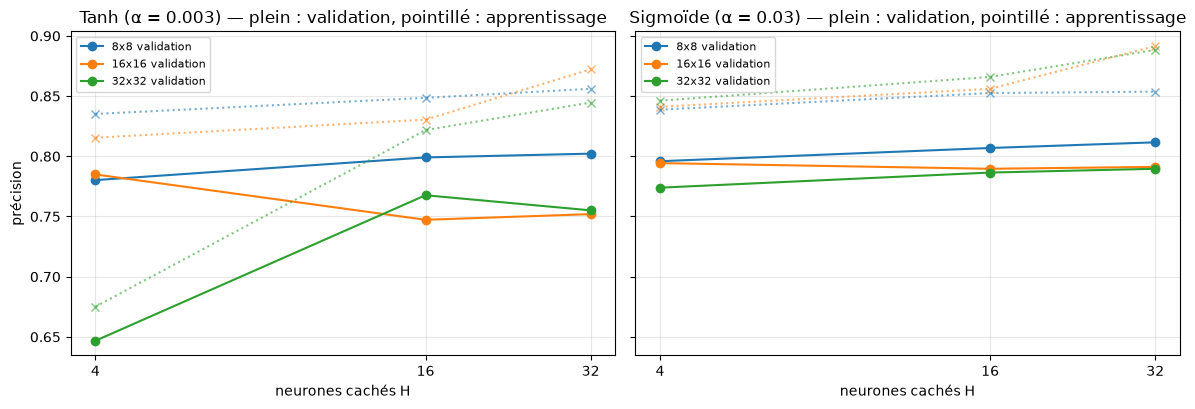

activation taille   H   poids  apprent.  valid.  écart
Tanh         8x8    4     787     83.5%   78.0%   5.5%
Tanh         8x8   16    3139     84.9%   79.9%   5.0%
Tanh         8x8   32    6275     85.6%   80.2%   5.4%
Tanh        16x16   4    3091     81.5%   78.5%   3.1%
Tanh        16x16  16   12355     83.0%   74.7%   8.3%
Tanh        16x16  32   24707     87.2%   75.2%  12.0%
Tanh        32x32   4   12307     67.5%   64.7%   2.8%
Tanh        32x32  16   49219     82.2%   76.8%   5.4%
Tanh        32x32  32   98435     84.5%   75.5%   9.0%
Sigmoïde     8x8    4     787     83.9%   79.6%   4.3%
Sigmoïde     8x8   16    3139     85.3%   80.7%   4.6%
Sigmoïde     8x8   32    6275     85.4%   81.2%   4.2%
Sigmoïde    16x16   4    3091     84.1%   79.4%   4.7%
Sigmoïde    16x16  16   12355     85.6%   79.0%   6.6%
Sigmoïde    16x16  32   24707     89.2%   79.1%  10.0%
Sigmoïde    32x32   4   12307     84.6%   77.4%   7.2%
Sigmoïde    32x32  16   49219     86.6%   78.6%   7.9%
Sigmoïde  

In [26]:
ALPHA_REF = {"tanh": 0.003, "sigmoid": 0.03}   # pas d'apprentissage de référence pour cette comparaison (la zone utile est cherchée en 10.2)
res_taille = {}
for act in ("tanh", "sigmoid"):
    for t in TAILLES:
        D = DATA[t]
        for h in HIDDEN:
            m = MLP([D["tr"].shape[1], h, K], activation=act, task="classification", seed=0)
            m.fit(D["tr"][idx_fit], Y_tr_c[idx_fit], alpha=ALPHA_REF[act], epochs=EPOCHS_GRILLE, log_every=EPOCHS_GRILLE)
            res_taille[(act, t, h)] = (m.score(D["tr"][idx_fit], Y_tr_c[idx_fit]), m.score(D["tr"][idx_val], Y_tr_c[idx_val]), m.n_weights)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for act, ax in zip(("tanh", "sigmoid"), axes):
    for t in TAILLES:
        ax.plot(HIDDEN, [res_taille[(act, t, h)][1] for h in HIDDEN], "o-", label=f"{t}x{t} validation")
        ax.plot(HIDDEN, [res_taille[(act, t, h)][0] for h in HIDDEN], "x:", color=ax.lines[-1].get_color(), alpha=0.6)
    ax.set_xscale("log", base=2); ax.set_xticks(HIDDEN); ax.set_xticklabels(HIDDEN)
    ax.set_title(f"{NOM[act]} (α = {ALPHA_REF[act]}) — plein : validation, pointillé : apprentissage")
    ax.set_xlabel("neurones cachés H"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel("précision")
fig.tight_layout()
sauver(fig, RES_DS, "etudes", "taille_image_et_neurones_caches.png")
plt.show()

print(f"{'activation':10s} {'taille':>6s} {'H':>3s} {'poids':>7s} {'apprent.':>9s} {'valid.':>7s} {'écart':>6s}")
for (act, t, h), (a, v, w) in res_taille.items():
    print(f"{NOM[act]:10s} {t:>3d}x{t:<2d} {h:3d} {w:7d} {a:9.1%} {v:7.1%} {a - v:6.1%}")

### 10.2 Pas d'apprentissage α
Pour chaque activation, 4 valeurs de α espacées d'un facteur 10 environ, sur une architecture fixe (taille 16×16, H = 16), mêmes poids initiaux. On cherche à voir les **trois régimes** : α trop petit (apprentissage très lent : avec un nombre d'époques limité, le modèle reste sous-entraîné), α adapté, α trop grand (apprentissage instable, la précision oscille ou s'effondre). La zone utile n'est pas la même pour Tanh et pour la Sigmoïde.

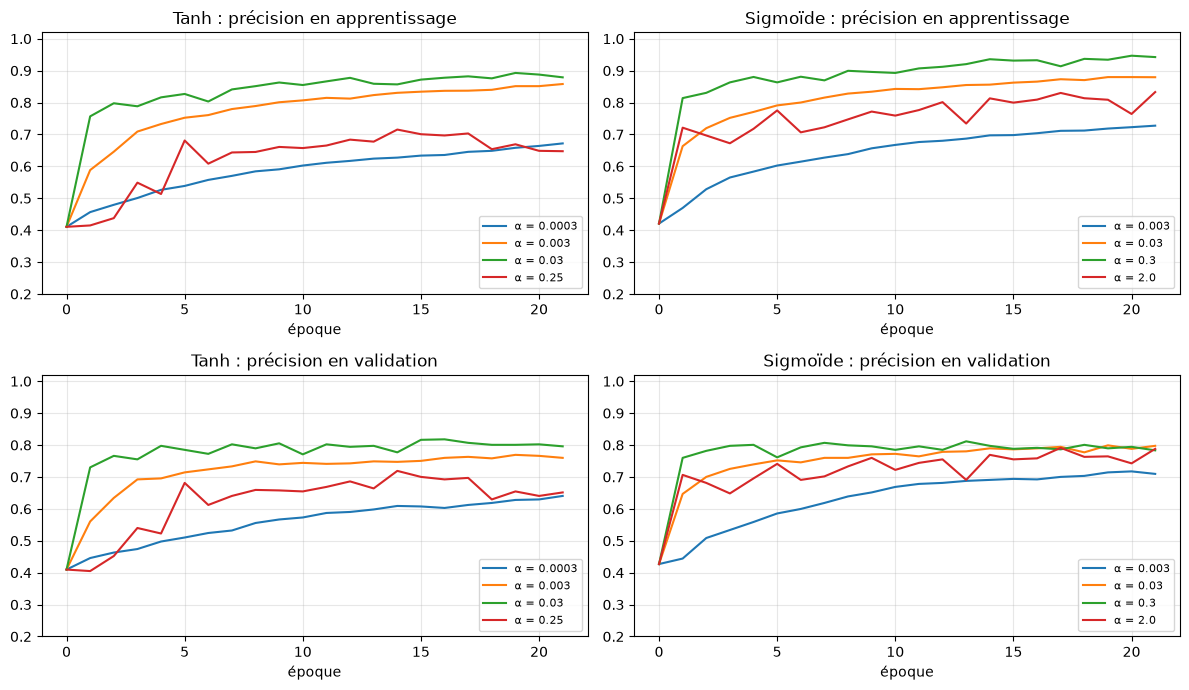

In [27]:
ALPHAS_TEST = {"tanh": [0.0003, 0.003, 0.03, 0.25], "sigmoid": [0.003, 0.03, 0.3, 2.0]}
D = DATA[16]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, act in enumerate(("tanh", "sigmoid")):
    for a in ALPHAS_TEST[act]:
        m = MLP([D["tr"].shape[1], 16, K], activation=act, task="classification", seed=0)
        h = m.fit(D["tr"][idx_fit], Y_tr_c[idx_fit], alpha=a, epochs=EPOCHS_FINAL, X_val=D["tr"][idx_val], Y_val=Y_tr_c[idx_val], log_every=max(1, EPOCHS_FINAL // 30))
        axes[0, j].plot(h["epoch"], h["train_score"], label=f"α = {a}")
        axes[1, j].plot(h["epoch"], h["val_score"], label=f"α = {a}")
    axes[0, j].set_title(f"{NOM[act]} : précision en apprentissage"); axes[1, j].set_title(f"{NOM[act]} : précision en validation")
    for i in range(2):
        axes[i, j].set_xlabel("époque"); axes[i, j].set_ylim(0.2, 1.02); axes[i, j].grid(alpha=0.3); axes[i, j].legend(fontsize=8)
fig.tight_layout()
sauver(fig, RES_DS, "etudes", "pas_apprentissage_alpha.png")
plt.show()

### 10.3 Sélection automatique sur la validation
Pour **chaque activation**, on essaie toutes les combinaisons (taille d'image, H, α) de la grille ci-dessous (`EPOCHS_FINAL` époques) et on retient celle qui a la meilleure précision de **validation** (à égalité : le réseau ayant le moins de poids).
Le jeu de test n'est pas utilisé ici.

In [28]:
GRILLE = {"tailles": (8, 16), "hidden": (4, 16, 32, 64),
          "alpha": {"tanh": (0.002, 0.008, 0.03, 0.1), "sigmoid": (0.01, 0.04, 0.16, 0.6)}}
if MODE_RAPIDE:   # grille réduite : test rapide du notebook uniquement
    GRILLE = {"tailles": (8,), "hidden": (4, 16), "alpha": {"tanh": (0.001, 0.004), "sigmoid": (0.01, 0.02)}}
selection = {}
for act in ("tanh", "sigmoid"):
    essais = []
    for t in GRILLE["tailles"]:
        D = DATA[t]
        for h in GRILLE["hidden"]:
            for a in GRILLE["alpha"][act]:
                m = MLP([D["tr"].shape[1], h, K], activation=act, task="classification", seed=0)
                m.fit(D["tr"][idx_fit], Y_tr_c[idx_fit], alpha=a, epochs=EPOCHS_FINAL, log_every=EPOCHS_FINAL)
                essais.append((m.score(D["tr"][idx_val], Y_tr_c[idx_val]), -m.n_weights, t, h, a, m.score(D["tr"][idx_fit], Y_tr_c[idx_fit])))
    essais.sort(reverse=True)
    selection[act] = essais
    print(f"--- {NOM[act]} : 5 meilleures configurations (validation) sur {len(essais)} essayées")
    print(f"{'valid.':>7s} {'apprent.':>9s} {'taille':>7s} {'H':>3s} {'α':>8s} {'poids':>7s}")
    for v, nw, t, h, a, tr in essais[:5]:
        print(f"{v:7.1%} {tr:9.1%} {t:>3d}x{t:<3d} {h:3d} {a:8} {-nw:7d}")
BEST = {act: dict(val=e[0][0], taille=e[0][2], H=e[0][3], alpha=e[0][4]) for act, e in selection.items()}
print("\nConfigurations retenues :", {NOM[a]: {k: round(float(v), 4) if k == "val" else v for k, v in b.items()} for a, b in BEST.items()})
for act in ("tanh", "sigmoid"):
    for nom_p, valeur, grille in (("α", BEST[act]["alpha"], GRILLE["alpha"][act]), ("H", BEST[act]["H"], GRILLE["hidden"])):
        if valeur in (min(grille), max(grille)):
            print(f"NOTE {NOM[act]} : {nom_p} retenu = {valeur}, au bord de la grille {tuple(grille)} : l'optimum est peut-être au-delà, à vérifier en élargissant la grille.")

--- Tanh : 5 meilleures configurations (validation) sur 32 essayées
 valid.  apprent.  taille   H        α   poids
  83.2%     92.2%   8x8    32    0.008    6275
  82.7%     91.4%   8x8    64     0.03   12547
  82.6%     90.3%   8x8    32     0.03    6275
  81.6%     88.3%   8x8     4     0.03     787
  81.6%     87.9%  16x16   32     0.03   24707
--- Sigmoïde : 5 meilleures configurations (validation) sur 32 essayées
 valid.  apprent.  taille   H        α   poids
  83.8%     93.9%   8x8    32     0.16    6275
  83.8%     91.5%   8x8    64     0.04   12547
  83.4%     88.5%   8x8    32     0.04    6275
  83.2%     96.7%   8x8    64     0.16   12547
  82.7%     96.9%   8x8    64      0.6   12547

Configurations retenues : {'Tanh': {'val': 0.832, 'taille': 8, 'H': 32, 'alpha': 0.008}, 'Sigmoïde': {'val': 0.8383, 'taille': 8, 'H': 32, 'alpha': 0.16}}


## 11. Résultats finaux sur le jeu de test (nettoyé)

Les deux modèles retenus sont ré-entraînés sur **tout** le train propre (époques = `EPOCHS_FINAL`) puis évalués **une seule fois** sur le test propre.

Tanh      | MLP (192, 32, 3) taille 8x8, α=0.008, 21 époques, 6275 poids | train 91.6% · test 84.1%
          rappel par classe sur le test : {'jasmin': '90% (326/363)', 'jonquille': '64% (134/208)', 'sunflower': '93% (206/221)'}
Sigmoïde  | MLP (192, 32, 3) taille 8x8, α=0.16, 21 époques, 6275 poids | train 95.1% · test 83.6%
          rappel par classe sur le test : {'jasmin': '89% (324/363)', 'jonquille': '67% (140/208)', 'sunflower': '90% (198/221)'}


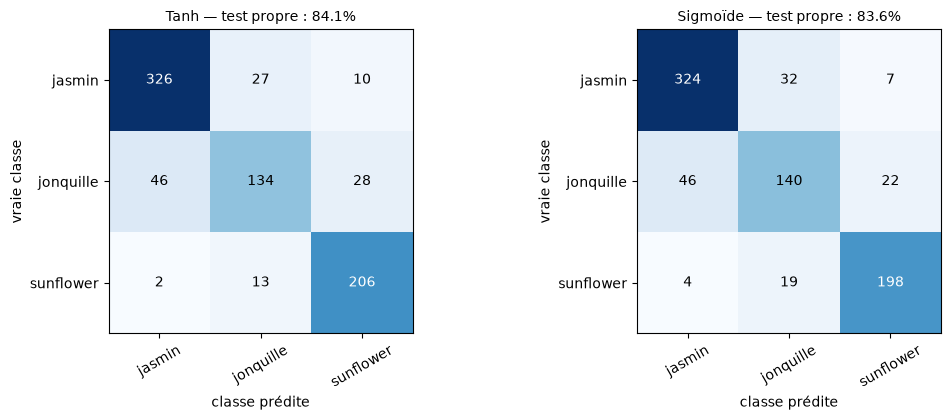

In [29]:
def matrice_confusion(m, X, y):
    pred = np.argmax(m.predict(X), axis=1)
    M = np.zeros((K, K), dtype=int)
    for vrai, p in zip(y, pred):
        M[vrai, p] += 1
    return M, pred

def tracer_confusion(ax, M, titre):
    ax.imshow(M, cmap="Blues")
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, rotation=30); ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, M[i, j], ha="center", va="center", color="white" if M[i, j] > M.max() / 2 else "black")
    ax.set_xlabel("classe prédite"); ax.set_ylabel("vraie classe"); ax.set_title(titre, fontsize=10)

FINAL = {}
for act in ("tanh", "sigmoid"):
    b = BEST[act]; D = DATA[b["taille"]]
    m = MLP([D["tr"].shape[1], b["H"], K], activation=act, task="classification", seed=0)
    m.fit(D["tr"], Y_tr_c, alpha=b["alpha"], epochs=EPOCHS_FINAL, log_every=EPOCHS_FINAL)
    M, pred = matrice_confusion(m, D["te"], y_te_c)
    FINAL[act] = dict(model=m, M=M, pred=pred, acc_train=m.score(D["tr"], Y_tr_c), acc_test=m.score(D["te"], Y_te_c))
    rappel = M.diagonal() / M.sum(axis=1)
    print(f"{NOM[act]:9s} | MLP ({D['tr'].shape[1]}, {b['H']}, {K}) taille {b['taille']}x{b['taille']}, α={b['alpha']}, {EPOCHS_FINAL} époques, {m.n_weights} poids | "
          f"train {FINAL[act]['acc_train']:.1%} · test {FINAL[act]['acc_test']:.1%}")
    print("          rappel par classe sur le test :", {CLASSES[c]: f"{rappel[c]:.0%} ({M[c, c]}/{M[c].sum()})" for c in range(K)})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, act in zip(axes, ("tanh", "sigmoid")):
    tracer_confusion(ax, FINAL[act]["M"], f"{NOM[act]} — test propre : {FINAL[act]['acc_test']:.1%}")
fig.tight_layout()
sauver(fig, RES_DS, "resultats", "matrices_de_confusion.png")
plt.show()

### Courbes d'apprentissage (illustration du sur-apprentissage)
Même configuration, mais entraînée plus longtemps (`EPOCHS_COURBE` époques) et suivie sur le jeu de test. La ligne verticale marque `EPOCHS_FINAL`, le nombre d'époques réellement retenu. Quand la précision d'apprentissage continue de monter alors que celle de test stagne ou baisse, le réseau **apprend par cœur** au lieu de généraliser.

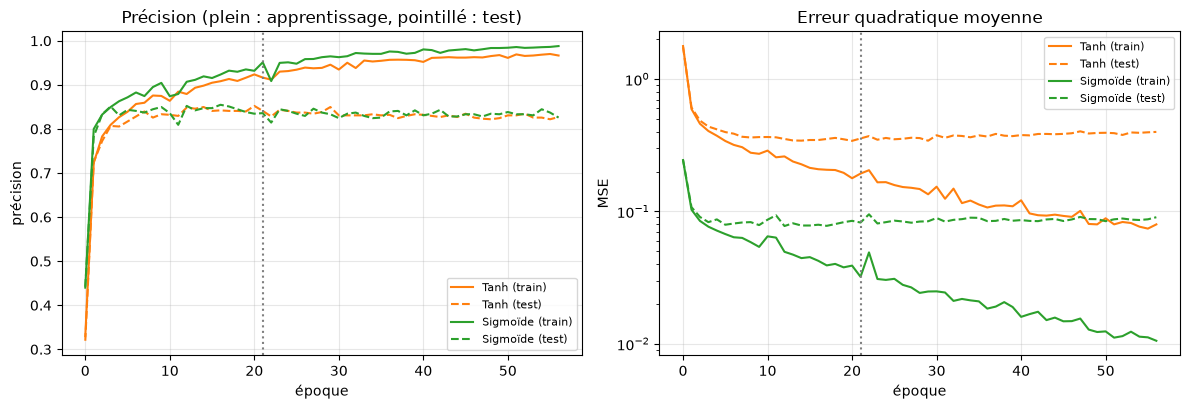

Tanh      époque 56 : apprentissage 96.7% · test 82.7%
Sigmoïde  époque 56 : apprentissage 98.8% · test 82.6%


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
hists = {}
for act in ("tanh", "sigmoid"):
    b = BEST[act]; D = DATA[b["taille"]]
    m = MLP([D["tr"].shape[1], b["H"], K], activation=act, task="classification", seed=0)
    hists[act] = m.fit(D["tr"], Y_tr_c, alpha=b["alpha"], epochs=EPOCHS_COURBE, X_val=D["te"], Y_val=Y_te_c, log_every=max(1, EPOCHS_COURBE // 40))
tracer_courbe(axes[0], hists, "train_score", "Précision (plein : apprentissage, pointillé : test)", "précision")
tracer_courbe(axes[1], hists, "train_loss", "Erreur quadratique moyenne", "MSE", log=True)
for ax in axes:
    ax.axvline(EPOCHS_FINAL, color="gray", ls=":")
fig.tight_layout()
sauver(fig, RES_DS, "resultats", "courbes_apprentissage_dataset.png")
plt.show()
for act in ("tanh", "sigmoid"):
    h = hists[act]
    print(f"{NOM[act]:9s} époque {EPOCHS_COURBE} : apprentissage {h['train_score'][-1]:.1%} · test {h['val_score'][-1]:.1%}")

### Images mal classées (test propre)

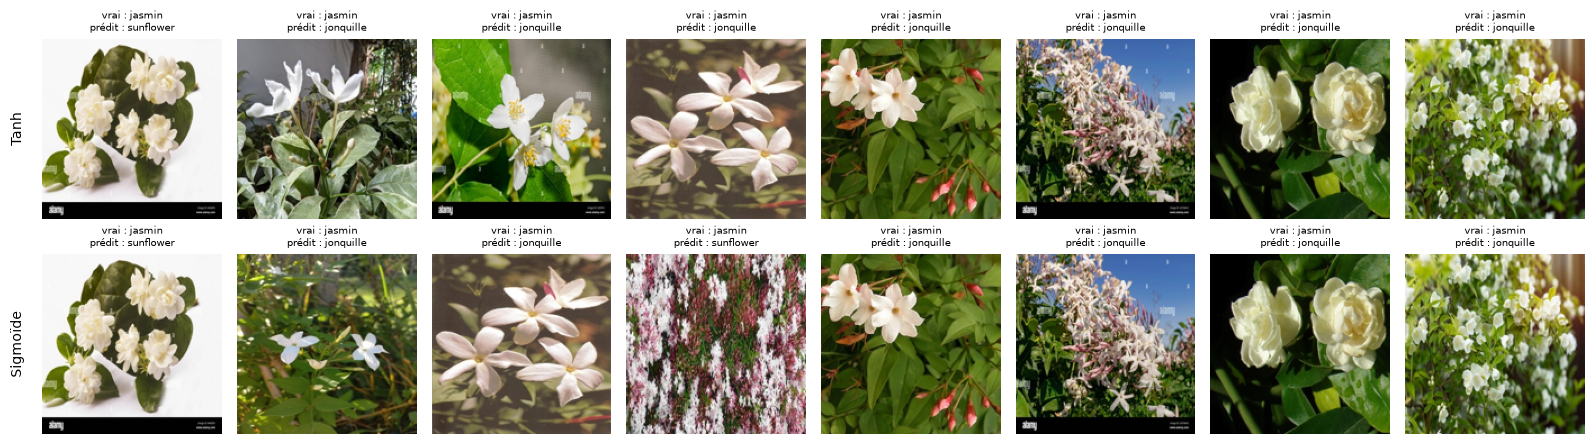

In [31]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ligne, act in zip(axes, ("tanh", "sigmoid")):
    mal = np.where(FINAL[act]["pred"] != y_te_c)[0]
    for ax in ligne:
        ax.axis("off")
    for ax, i in zip(ligne, mal[:8]):
        im = Image.open(chemins_te[idx_te[i]]).convert("RGB"); im.thumbnail((160, 160))
        ax.imshow(im); ax.set_title(f"vrai : {CLASSES[y_te_c[i]]}\nprédit : {CLASSES[FINAL[act]['pred'][i]]}", fontsize=7)
    ligne[0].text(-0.1, 0.5, NOM[act], transform=ligne[0].transAxes, rotation=90, va="center", ha="right", fontsize=10)
fig.tight_layout()
sauver(fig, RES_DS, "resultats", "images_mal_classees.png")
plt.show()

## 12. Ce que les biais du dataset changent aux résultats

### 12.1 Fuite train/test : combien la précision est-elle gonflée ?
Même architecture et mêmes réglages que le modèle retenu, mais entraînée sur le train **brut** (avec doublons) et évaluée sur le test **brut** (avec images déjà vues), comparée au résultat sur le jeu nettoyé.
On sépare aussi, dans le test brut, les images dont une copie (identique, retournée ou tournée) est dans le train de celles qui n'en ont pas.

In [32]:
vu = copie_te | (d_min_test < iu.SEUIL_DOUBLON)    # images du test brut dont une copie (identique, retournée ou tournée) est dans le train brut
y_tr_brut_pm1 = iu.etiquettes_pm1(y_tr, K); y_te_brut_pm1 = iu.etiquettes_pm1(y_te, K)
print(f"Test brut : {len(y_te)} images dont {int(vu.sum())} déjà présentes dans le train ({vu.mean():.0%})\n")
print(f"{'activation':10s} {'test BRUT':>10s} {'dont déjà vues':>15s} {'dont nouvelles':>15s} | {'test STRICT':>12s}")
ecarts_vu = {}
for act in ("tanh", "sigmoid"):
    b = BEST[act]; D = DATA[b["taille"]]
    m = MLP([D["tr_brut"].shape[1], b["H"], K], activation=act, task="classification", seed=0)
    m.fit(D["tr_brut"], y_tr_brut_pm1, alpha=b["alpha"], epochs=EPOCHS_FINAL, log_every=EPOCHS_FINAL)
    s_all = m.score(D["te_brut"], y_te_brut_pm1)
    s_vu = m.score(D["te_brut"][vu], y_te_brut_pm1[vu]) if vu.any() else float("nan")
    s_new = m.score(D["te_brut"][~vu], y_te_brut_pm1[~vu])
    print(f"{NOM[act]:10s} {s_all:10.1%} {s_vu:15.1%} {s_new:15.1%} | {FINAL[act]['acc_test']:12.1%}")
    ecarts_vu[act] = s_vu - s_new
if vu.sum() < 10:
    print("\nTrop peu d'images avec copie pour conclure sur ce point.")
elif max(ecarts_vu.values()) > 0.05:
    print("\nPrécision nettement plus haute sur les images dont une copie est dans le train : le réseau les a en partie mémorisées, la précision « brute » est trompeuse.")
else:
    print(f"\nÉcart faible entre images avec et sans copie dans le train ({', '.join(f'{NOM[a]} : {100 * e:+.1f} points' for a, e in ecarts_vu.items())}) : ce modèle, peu complexe, ne semble pas avoir mémorisé ces copies. "
          f"L'effet de la contamination est ici limité (mesuré sur seulement {int(vu.sum())} images, donc imprécis), mais le test strict reste la référence ; un modèle plus complexe en profiterait davantage.")

Test brut : 795 images dont 0 déjà présentes dans le train (0%)

activation  test BRUT  dont déjà vues  dont nouvelles |  test STRICT
Tanh            82.4%            nan%           82.4% |        84.1%
Sigmoïde        84.8%            nan%           84.8% |        83.6%

Trop peu d'images avec copie pour conclure sur ce point.


### 12.2 Déséquilibre des classes : un réseau qui ignore la classe rare
On compare le modèle retenu entraîné sur le train propre tel quel, et sur le train propre **rééquilibré par répétition** des images de la classe rare (uniquement dans l'apprentissage ; le test reste inchangé).

In [33]:
eff = lambda y: {CLASSES[c]: int(n) for c, n in enumerate(np.bincount(y, minlength=K))}
rap = lambda M: {CLASSES[c]: round(float(r), 2) for c, r in enumerate(M.diagonal() / M.sum(axis=1))}
print(f"Effectifs du train propre : {eff(y_tr_c)}")
for act in ("tanh", "sigmoid"):
    b = BEST[act]; D = DATA[b["taille"]]
    Xb, yb = iu.equilibrer_par_repetition(D["tr"], y_tr_c)
    m = MLP([Xb.shape[1], b["H"], K], activation=act, task="classification", seed=0)
    m.fit(Xb, iu.etiquettes_pm1(yb, K), alpha=b["alpha"], epochs=EPOCHS_FINAL, log_every=EPOCHS_FINAL)
    Mb, _ = matrice_confusion(m, D["te"], y_te_c)
    print(f"\n{NOM[act]} — effectifs après rééquilibrage : {eff(yb)}")
    print(f"  rappel par classe, tel quel      : {rap(FINAL[act]['M'])}  (précision globale {FINAL[act]['acc_test']:.1%})")
    print(f"  rappel par classe, rééquilibré   : {rap(Mb)}  (précision globale {np.trace(Mb) / Mb.sum():.1%})")
print(f"\nEffectifs du test propre : {eff(y_te_c)} -> avec si peu d'images dans une classe, son rappel n'est mesuré que sur quelques exemples (très imprécis).")

Effectifs du train propre : {'jasmin': 1454, 'jonquille': 839, 'sunflower': 880}

Tanh — effectifs après rééquilibrage : {'jasmin': 1454, 'jonquille': 1678, 'sunflower': 1760}
  rappel par classe, tel quel      : {'jasmin': 0.9, 'jonquille': 0.64, 'sunflower': 0.93}  (précision globale 84.1%)
  rappel par classe, rééquilibré   : {'jasmin': 0.83, 'jonquille': 0.74, 'sunflower': 0.84}  (précision globale 81.1%)

Sigmoïde — effectifs après rééquilibrage : {'jasmin': 1454, 'jonquille': 1678, 'sunflower': 1760}
  rappel par classe, tel quel      : {'jasmin': 0.89, 'jonquille': 0.67, 'sunflower': 0.9}  (précision globale 83.6%)
  rappel par classe, rééquilibré   : {'jasmin': 0.87, 'jonquille': 0.73, 'sunflower': 0.87}  (précision globale 83.1%)

Effectifs du test propre : {'jasmin': 363, 'jonquille': 208, 'sunflower': 221} -> avec si peu d'images dans une classe, son rappel n'est mesuré que sur quelques exemples (très imprécis).


### 12.3 Le modèle s'appuie-t-il sur les coins noirs ?
On sépare le test propre en images **avec** et **sans** coins noirs et on compare la précision. Une précision très supérieure sur les images à coins noirs suggère un raccourci. (Mesure fiable seulement s'il y a assez d'images dans chaque groupe.)

In [34]:
mask_coins = iu.coins_noirs(X32_te[idx_te])
n_avec, n_sans = int(mask_coins.sum()), int((~mask_coins).sum())
print(f"Test propre : {n_avec} images avec coins noirs, {n_sans} sans. Par classe (avec coins noirs) : "
      f"{ {CLASSES[c]: int(mask_coins[y_te_c == c].sum()) for c in range(K)} }")
if n_avec >= 10 and n_sans >= 10:
    for act in ("tanh", "sigmoid"):
        ok = FINAL[act]["pred"] == y_te_c
        print(f"{NOM[act]:9s} précision avec coins noirs : {ok[mask_coins].mean():.1%} ({n_avec} images) | sans : {ok[~mask_coins].mean():.1%} ({n_sans} images)")
else:
    print("Trop peu d'images avec (ou sans) coins noirs dans le test : pas de conclusion possible sur ce point.")

Test propre : 111 images avec coins noirs, 681 sans. Par classe (avec coins noirs) : {'jasmin': 109, 'jonquille': 1, 'sunflower': 1}
Tanh      précision avec coins noirs : 89.2% (111 images) | sans : 83.3% (681 images)
Sigmoïde  précision avec coins noirs : 86.5% (111 images) | sans : 83.1% (681 images)


### 12.4 Test contrefactuel : que fait le modèle si on ajoute des coins noirs à des images de test ?
Le test strict ne contient presque aucune image à coins noirs, donc 12.3 ne peut pas conclure. On fabrique donc des versions **tournées** des images du test strict, de deux façons : avec un fond **noir** (coins noirs) et avec un fond de **couleur moyenne** de l'image (même rotation, sans coins noirs : c'est le témoin). Si le modèle s'appuie sur les coins noirs, la part d'images prédites dans la classe qui en a le plus à l'entraînement augmente avec le fond noir, et pas avec le fond moyen.

In [35]:
rng_rot = np.random.default_rng(0)
angles = rng_rot.choice([-1, 1], size=len(idx_te)) * rng_rot.uniform(6, 15, size=len(idx_te))
CACHE_ROT = {}

def versions_tournees(taille):
    # images du test strict tournées (fond moyen = témoin, fond noir = coins noirs), prétraitées à la taille voulue
    if taille not in CACHE_ROT:
        sortie = {}
        for nom_c, noir in (("rotation, fond moyen (témoin)", False), ("rotation, coins noirs", True)):
            Xv = []
            for k, i in enumerate(idx_te):
                im = Image.open(chemins_te[i]).convert("RGB").resize((256, 256))
                fond = (0, 0, 0) if noir else tuple(int(v) for v in np.asarray(im).reshape(-1, 3).mean(axis=0))
                Xv.append(iu.preprocess_image(im.rotate(float(angles[k]), fillcolor=fond), taille)[0])
            sortie[nom_c] = np.array(Xv)
        CACHE_ROT[taille] = sortie
    return CACHE_ROT[taille]

def afficher_contrefactuel(titre, modele, taille, pred_originale):
    # part d'images prédites dans chaque classe (originales / rotation témoin / rotation à coins noirs) et effet des coins noirs
    preds = {"images originales": pred_originale}
    for nom_c, Xv in versions_tournees(taille).items():
        preds[nom_c] = np.argmax(modele.predict(Xv), axis=1)
    part = lambda p: np.array([float(np.mean(p == j)) for j in range(K)])
    print(f"\n{titre} : part des images de test strict prédites dans chaque classe")
    print(f"{'':32s} " + " ".join(f"{c:>10s}" for c in CLASSES) + f" {'précision':>10s}")
    for nom_c, p in preds.items():
        print(f"{nom_c:32s} " + " ".join(f"{v:10.1%}" for v in part(p)) + f" {np.mean(p == y_te_c):10.1%}")
    ecart = part(preds["rotation, coins noirs"]) - part(preds["rotation, fond moyen (témoin)"])
    print("Effet des coins noirs (points de % de prédictions, coins noirs - fond moyen) :", {CLASSES[j]: f"{100 * ecart[j]:+.1f}" for j in range(K)})
    return ecart

for act in ("tanh", "sigmoid"):
    afficher_contrefactuel(NOM[act], FINAL[act]["model"], BEST[act]["taille"], FINAL[act]["pred"])
print("\nUn décalage net vers une classe, propre aux coins noirs, indique un raccourci. Un décalage comparable avec le fond moyen vient de la rotation elle-même, pas des coins.")


Tanh : part des images de test strict prédites dans chaque classe
                                     jasmin  jonquille  sunflower  précision
images originales                     47.2%      22.0%      30.8%      84.1%
rotation, fond moyen (témoin)         43.8%      25.5%      30.7%      81.8%
rotation, coins noirs                 54.5%      18.3%      27.1%      81.4%
Effet des coins noirs (points de % de prédictions, coins noirs - fond moyen) : {'jasmin': '+10.7', 'jonquille': '-7.2', 'sunflower': '-3.5'}

Sigmoïde : part des images de test strict prédites dans chaque classe
                                     jasmin  jonquille  sunflower  précision
images originales                     47.2%      24.1%      28.7%      83.6%
rotation, fond moyen (témoin)         43.1%      28.8%      28.2%      83.5%
rotation, coins noirs                 52.1%      22.7%      25.1%      82.6%
Effet des coins noirs (points de % de prédictions, coins noirs - fond moyen) : {'jasmin': '+9.1', 'jonqui

### 12.5 Atténuer le raccourci : entraîner sans les images à coins noirs
Si le modèle s'appuie sur les coins noirs (12.4), on le ré-entraîne avec la **même configuration** mais **sans les images du train à coins noirs** (ce sont surtout des copies tournées d'autres images du train : on perd peu d'information, et la classe sur-représentée est aussi rééquilibrée). On compare, sur le même test strict, la précision par classe et l'effet des coins noirs.

In [36]:
coins_tr_propre = iu.coins_noirs(X32_tr[idx_tr])
garde = ~coins_tr_propre
eff_c = lambda y: {CLASSES[c]: int(n) for c, n in enumerate(np.bincount(y, minlength=K))}
print(f"Train propre : {int(coins_tr_propre.sum())} images à coins noirs retirées. Effectifs {eff_c(y_tr_c)} -> {eff_c(y_tr_c[garde])}")
rap_c = lambda M: {CLASSES[c]: f"{M[c, c] / M[c].sum():.0%}" for c in range(K)}
SANS_COINS = {}
for act in ("tanh", "sigmoid"):
    b = BEST[act]; D = DATA[b["taille"]]
    ep = max(5, round(EPOCHS_FINAL * len(y_tr_c) / int(garde.sum())))      # même nombre de mises à jour de poids que le modèle standard
    m = MLP([D["tr"].shape[1], b["H"], K], activation=act, task="classification", seed=0)
    m.fit(D["tr"][garde], Y_tr_c[garde], alpha=b["alpha"], epochs=ep, log_every=ep)
    M, pred = matrice_confusion(m, D["te"], y_te_c)
    SANS_COINS[act] = dict(model=m, M=M, pred=pred)
    print(f"\n{NOM[act]} : précision test strict {np.trace(M) / M.sum():.1%} (modèle standard : {FINAL[act]['acc_test']:.1%})")
    print(f"   rappel par classe, sans coins noirs : {rap_c(M)} | modèle standard : {rap_c(FINAL[act]['M'])}")
    afficher_contrefactuel(NOM[act] + " (entraîné sans coins noirs)", m, b["taille"], pred)
print("\nSi l'effet des coins noirs devient proche de zéro tout en gardant une précision comparable, le raccourci est supprimé sans perte.")

Train propre : 479 images à coins noirs retirées. Effectifs {'jasmin': 1454, 'jonquille': 839, 'sunflower': 880} -> {'jasmin': 986, 'jonquille': 834, 'sunflower': 874}

Tanh : précision test strict 80.3% (modèle standard : 84.1%)
   rappel par classe, sans coins noirs : {'jasmin': '81%', 'jonquille': '74%', 'sunflower': '86%'} | modèle standard : {'jasmin': '90%', 'jonquille': '64%', 'sunflower': '93%'}

Tanh (entraîné sans coins noirs) : part des images de test strict prédites dans chaque classe
                                     jasmin  jonquille  sunflower  précision
images originales                     42.9%      29.5%      27.5%      80.3%
rotation, fond moyen (témoin)         41.2%      30.4%      28.4%      78.9%
rotation, coins noirs                 39.3%      33.6%      27.1%      77.7%
Effet des coins noirs (points de % de prédictions, coins noirs - fond moyen) : {'jasmin': '-1.9', 'jonquille': '+3.2', 'sunflower': '-1.3'}

Sigmoïde : précision test strict 84.0% (modèle st

## 13. Sauvegarde des modèles pour l'application

Les modèles retenus sont sauvegardés dans `models/MLP/` avec leurs **métadonnées** (noms des classes, taille d'image) pour que l'API sache comment préparer une image (`images_utils.preprocess_image`). On vérifie qu'un modèle rechargé donne exactement les mêmes prédictions, en passant par le prétraitement d'une vraie image.

In [37]:
MODELES = "../models/MLP"
os.makedirs(MODELES, exist_ok=True)
for act in ("tanh", "sigmoid"):
    b = BEST[act]
    meta = {"classes": CLASSES, "taille_image": b["taille"], "activation": act,
            "pretraitement": "images_utils.preprocess_image (RGB, redimensionnée, pixels dans [-1, 1])",
            "precision_test_propre": round(FINAL[act]["acc_test"], 4)}
    chemin = FINAL[act]["model"].save(os.path.join(MODELES, f"mlp_{act}"), meta=meta)
    rechargé = MLP.load(chemin)

    # test de bout en bout : image -> prétraitement -> modèle rechargé
    i = 0
    x = iu.preprocess_image(chemins_te[idx_te[i]], rechargé.meta["taille_image"])
    D = DATA[b["taille"]]
    identique = np.array_equal(rechargé.predict(x), FINAL[act]["model"].predict(D["te"][i:i + 1]))
    scores = rechargé.predict(x)[0]
    print(f"{NOM[act]:9s} -> {chemin} | métadonnées : classes={rechargé.meta['classes']}, taille={rechargé.meta['taille_image']} | "
          f"même prédiction qu'avant la sauvegarde : {identique} | image test 0 : {CLASSES[int(np.argmax(scores))]} (vrai : {CLASSES[y_te_c[i]]})")

Tanh      -> ../models/MLP/mlp_tanh.npz | métadonnées : classes=['jasmin', 'jonquille', 'sunflower'], taille=8 | même prédiction qu'avant la sauvegarde : True | image test 0 : jasmin (vrai : jasmin)
Sigmoïde  -> ../models/MLP/mlp_sigmoid.npz | métadonnées : classes=['jasmin', 'jonquille', 'sunflower'], taille=8 | même prédiction qu'avant la sauvegarde : True | image test 0 : jasmin (vrai : jasmin)


## 14. Analyse critique (dataset réel)

Les points suivants sont ceux que le protocole ci-dessus met en évidence sur notre dataset :

1. **La qualité des données prime sur le modèle.** Les contrôles de la section 8 doivent précéder tout apprentissage : tailles d'origine, doublons, équilibre des classes. Un test contenant des images déjà vues donne une précision trompeuse (12.1).
2. **La précision globale peut cacher une classe jamais reconnue.** Il faut lire la matrice de confusion et le rappel par classe (11, 12.2) ; avec peu d'images dans une classe, son rappel est de plus mesuré sur très peu d'exemples.
3. **Modèle trop complexe pour le nombre d'exemples.** Avec des pixels bruts, le nombre de poids dépasse largement le nombre d'exemples (section 9) : l'écart entre précision d'apprentissage et de validation (10.1) et les courbes d'apprentissage (11) illustrent le **sur-apprentissage** ; des images plus petites, donc moins de poids, généralisent aussi bien, voire mieux.
4. **Le pas d'apprentissage doit être réglé, et pas de la même façon pour les deux activations.** Trop petit, le modèle reste sous-entraîné dans le nombre d'époques disponible ; trop grand, l'apprentissage devient instable (10.2). Comparer Tanh et Sigmoïde à α égal est trompeur.
5. **Limites du MLP sur des pixels bruts.** Il n'exploite ni la forme ni la position des objets ; il distingue surtout des couleurs et des textures globales (par exemple une fleur blanche d'une fleur jaune), et confond les classes qui partagent ces couleurs.
6. **Raccourcis possibles dans les images.** Les coins noirs laissés par des rotations (8.1b, 12.3) et les filigranes visibles sur certaines images sont des indices que le modèle peut utiliser à la place de la fleur ; la taille d'origine des images (8.1) en est un autre quand les classes ne viennent pas de la même source.
7. **Copies tournées ou retournées entre train et test.** Dans la première version du dataset, 11 % du test (91 images sur 794, presque toutes du jasmin) étaient des copies tournées ou retournées d'images du train, car la séparation avait été faite après l'augmentation de données. Les images ont depuis été redistribuées **par groupes de copies** : le contrôle (8.2c) trouve maintenant 0 copie dans le test. Un test **strict** et une validation **par groupes** restent nécessaires dès qu'un dataset est augmenté.
8. **Lecture des erreurs.** La classe la plus faible est la jonquille (rappel entre 64 % et 72 % selon l'activation et la graine), alors que le jasmin (environ 90 %) et le tournesol (environ 86 à 93 %) sont mieux reconnus. Rééquilibrer les classes par répétition (12.2) améliore le rappel de la jonquille (de 0,64 à 0,74 pour Tanh, de 0,67 à 0,73 pour la Sigmoïde, une seule graine) mais baisse la précision globale (84,1 % à 81,1 % pour Tanh, 83,6 % à 83,1 % pour la Sigmoïde) : c'est un compromis, pas un gain. Nous n'affirmons pas de cause précise pour chaque erreur : nous ne l'avons pas vérifiée image par image.
9. **Un raccourci appris : les coins noirs.** 32 % des images de jasmin ont les coins noirs laissés par une rotation, contre moins de 1 % pour les deux autres classes. Ajouter des coins noirs à des images tournées décale les prédictions vers le jasmin de +10,7 points (Tanh) et +9,1 points (Sigmoïde) par rapport à un fond neutre (12.4) : les modèles utilisent un indice absent des vraies photos. Ce raccourci reste présent dans le test (111 images à coins noirs, dont 109 de jasmin), et la précision y est plus haute (89,2 % et 86,5 % contre 83,3 % et 83,1 % sans coins noirs, 12.3) : la précision du test est donc en partie gonflée. En entraînant sans les 479 images à coins noirs (12.5), le décalage disparaît (−1,9 et −1,1 point) ; la précision passe de 84,1 % à 80,3 % pour Tanh et de 83,6 % à 84,0 % pour la Sigmoïde, ce qui ne permet pas de conclure avec une seule graine.
10. **Tanh ou Sigmoïde ?** Mesure répétée avec 10 initialisations différentes (même données, même configuration retenue, test strict de 792 images) : Tanh 83,2 % ± 1,0 point, Sigmoïde 85,3 % ± 0,6 point (écart-type sur les 10 graines). L'écart moyen est de 2,2 points (erreur standard ≈ 0,4 point) et la Sigmoïde gagne 10 fois sur 10 : sur ce test et avec ces réglages, la Sigmoïde est un peu meilleure. Le résultat vaut pour ce dataset et pour des réglages choisis sur une seule graine : il ne dit rien d'une supériorité générale. Ces chiffres ont été obtenus sur Linux ; la fonction `rand()` du C++ diffère selon la plateforme, donc l'exécution du notebook sur Mac (Tanh 84,1 %, Sigmoïde 83,6 %, une seule graine) donne des valeurs légèrement différentes ; un écart de ce type avec une seule graine ne contredit pas la moyenne sur 10.
